In [1]:
import sys
import torch
import torchvision

print("=" * 60)
print("DEEP LEARNING ENVIRONMENT")
print("=" * 60)

print("Python      :", sys.executable)
print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA runtime:", torch.version.cuda)

    memory = (
        torch.cuda.get_device_properties(0).total_memory
        / 1024**3
    )

    print(f"GPU memory: {memory:.2f} GB")

    # Small GPU test
    x = torch.randn(1000, 1000, device="cuda")
    y = x @ x

    print("\n✅ GPU computation successful!")

    del x, y
    torch.cuda.empty_cache()
else:
    print("\n❌ CUDA is not available")

DEEP LEARNING ENVIRONMENT
Python      : C:\Users\pabit\dlproject_env\Scripts\python.exe
PyTorch     : 2.11.0+cu128
Torchvision : 0.26.0+cu128

CUDA available: True
GPU: NVIDIA GeForce RTX 2050
CUDA runtime: 12.8
GPU memory: 4.00 GB

✅ GPU computation successful!


In [2]:
import os

PROJECT_DIR = os.getcwd()

print("Current Jupyter folder:")
print(PROJECT_DIR)

print("\nFiles/folders:")
for item in os.listdir(PROJECT_DIR):
    print(" -", item)

Current Jupyter folder:
D:\python

Files/folders:
 - .ipynb_checkpoints
 - DLproject.ipynb
 - mlpaproject.ipynb
 - Untitled.ipynb
 - Untitled1.ipynb


In [3]:
import os

PROJECT_DIR = os.getcwd()
ZIP_PATH = os.path.join(PROJECT_DIR, "InsPLAD-det.zip")

print("Looking for:")
print(ZIP_PATH)

if os.path.exists(ZIP_PATH):
    size = os.path.getsize(ZIP_PATH) / (1024 * 1024)
    print(f"\n✅ Dataset ZIP found!")
    print(f"Size: {size:.2f} MB")
else:
    print("\n❌ InsPLAD-det.zip not found.")
    print("Please put InsPLAD-det.zip inside D:\\python")

Looking for:
D:\python\InsPLAD-det.zip

❌ InsPLAD-det.zip not found.
Please put InsPLAD-det.zip inside D:\python


In [4]:
import os
import zipfile

ZIP_PATH = r"C:\Users\pabit\Downloads\InsPLAD A Dataset and Benchmark for Power Line Asset Inspection in UAV Images\InsPLAD A Dataset and Benchmark for Power Line Asset Inspection in UAV Images\InsPLAD_Dataset.zip"

DATA_DIR = r"D:\python\InsPLAD"

print("=" * 60)
print("INSPLAD DATASET")
print("=" * 60)

print("ZIP exists:", os.path.exists(ZIP_PATH))

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(
        "Dataset ZIP not found. Please check the path."
    )

zip_size = os.path.getsize(ZIP_PATH) / (1024**3)

print(f"ZIP size: {zip_size:.2f} GB")

os.makedirs(DATA_DIR, exist_ok=True)

print("\nExtracting dataset...")
print("This may take some time.")

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATA_DIR)

print("\n✅ Extraction completed!")
print("Dataset location:", DATA_DIR)

INSPLAD DATASET
ZIP exists: True
ZIP size: 5.96 GB

Extracting dataset...
This may take some time.

✅ Extraction completed!
Dataset location: D:\python\InsPLAD


In [5]:
import os

print("=" * 60)
print("EXTRACTED DATASET STRUCTURE")
print("=" * 60)

for root, dirs, files in os.walk(DATA_DIR):
    level = root.replace(DATA_DIR, "").count(os.sep)

    if level > 3:
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}    {file}")

EXTRACTED DATASET STRUCTURE
InsPLAD/
    InsPLAD-det.zip
    supervised_fault_classification.zip
    unsupervised_anomaly_detection.zip


In [8]:
import os
import zipfile

INSPLAD_ROOT = r"D:\python\InsPLAD"

DET_ZIP = os.path.join(
    INSPLAD_ROOT,
    "InsPLAD-det.zip"
)

DET_DIR = os.path.join(
    INSPLAD_ROOT,
    "InsPLAD-det"
)

print("=" * 60)
print("INSPLAD OBJECT DETECTION DATASET")
print("=" * 60)

print("ZIP exists:", os.path.exists(DET_ZIP))

if not os.path.exists(DET_ZIP):
    raise FileNotFoundError(
        f"Could not find:\n{DET_ZIP}"
    )

os.makedirs(DET_DIR, exist_ok=True)

print(f"ZIP size: {os.path.getsize(DET_ZIP)/(1024**3):.2f} GB")

if len(os.listdir(DET_DIR)) == 0:
    print("\nExtracting InsPLAD-det...")
    print("Please wait. This can take some time.")

    with zipfile.ZipFile(DET_ZIP, "r") as zip_ref:
        zip_ref.extractall(DET_DIR)

    print("\n✅ InsPLAD-det extraction completed!")
else:
    print("\n⚠️ InsPLAD-det folder is not empty.")
    print("Skipping extraction.")

print("\nDataset folder:")
print(DET_DIR)

INSPLAD OBJECT DETECTION DATASET
ZIP exists: True
ZIP size: 4.06 GB

Extracting InsPLAD-det...
Please wait. This can take some time.

✅ InsPLAD-det extraction completed!

Dataset folder:
D:\python\InsPLAD\InsPLAD-det


In [9]:
import os

print("=" * 60)
print("INSPLAD-DET STRUCTURE")
print("=" * 60)

for root, dirs, files in os.walk(DET_DIR):

    relative = os.path.relpath(root, DET_DIR)
    level = 0 if relative == "." else relative.count(os.sep) + 1

    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:20]:
        print(f"{indent}    {file}")

INSPLAD-DET STRUCTURE
InsPLAD-det/
    annotations/
        instances_train.json
        instances_val.json
    train/
        1-1_DJI_0569.jpg
        1-1_DJI_0571.jpg
        1-1_DJI_0572.jpg
        1-1_DJI_0573.jpg
        1-1_DJI_0574.jpg
        1-1_DJI_0575.jpg
        1-1_DJI_0576.jpg
        1-1_DJI_0577.jpg
        1-1_DJI_0578.jpg
        1-1_DJI_0579.jpg
        1-1_DJI_0580.jpg
        1-1_DJI_0581.jpg
        1-1_DJI_0585.jpg
        1-1_DJI_0586.jpg
        1-1_DJI_0587.jpg
        1-1_DJI_0588.jpg
        1-1_DJI_0589.jpg
        1-1_DJI_0590.jpg
        1-1_DJI_0591.jpg
        1-1_DJI_0592.jpg
    val/
        238-1_DJI_0366.jpg
        238-1_DJI_0367.jpg
        238-1_DJI_0368.jpg
        238-1_DJI_0369.jpg
        238-1_DJI_0370.jpg
        238-1_DJI_0371.jpg
        238-1_DJI_0372.jpg
        238-1_DJI_0373.jpg
        238-1_DJI_0374.jpg
        238-1_DJI_0375.jpg
        238-1_DJI_0376.jpg
        238-1_DJI_0377.jpg
        238-1_DJI_0378.jpg
        238-1_DJI_037

In [10]:
import os

# ============================================================
# INSPLAD DATASET PATHS
# ============================================================

DATA_DIR = r"D:\python\InsPLAD\InsPLAD-det"

TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR = os.path.join(DATA_DIR, "val")

ANNOTATION_DIR = os.path.join(DATA_DIR, "annotations")

TRAIN_ANNOTATION = os.path.join(
    ANNOTATION_DIR,
    "instances_train.json"
)

VAL_ANNOTATION = os.path.join(
    ANNOTATION_DIR,
    "instances_val.json"
)

CHECKPOINT_DIR = r"D:\python\DLproject_checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)


print("=" * 60)
print("DATASET PATHS")
print("=" * 60)

print("DATA_DIR:")
print(DATA_DIR)

print("\nTRAIN_DIR:")
print(TRAIN_DIR)

print("\nVAL_DIR:")
print(VAL_DIR)

print("\nTRAIN ANNOTATION:")
print(TRAIN_ANNOTATION)

print("\nVAL ANNOTATION:")
print(VAL_ANNOTATION)

print("\nCHECKPOINT_DIR:")
print(CHECKPOINT_DIR)

DATASET PATHS
DATA_DIR:
D:\python\InsPLAD\InsPLAD-det

TRAIN_DIR:
D:\python\InsPLAD\InsPLAD-det\train

VAL_DIR:
D:\python\InsPLAD\InsPLAD-det\val

TRAIN ANNOTATION:
D:\python\InsPLAD\InsPLAD-det\annotations\instances_train.json

VAL ANNOTATION:
D:\python\InsPLAD\InsPLAD-det\annotations\instances_val.json

CHECKPOINT_DIR:
D:\python\DLproject_checkpoints


In [11]:
paths = {
    "Dataset": DATA_DIR,
    "Train folder": TRAIN_DIR,
    "Validation folder": VAL_DIR,
    "Annotation folder": ANNOTATION_DIR,
    "Train JSON": TRAIN_ANNOTATION,
    "Validation JSON": VAL_ANNOTATION,
}

print("=" * 60)
print("PATH VERIFICATION")
print("=" * 60)

all_ok = True

for name, path in paths.items():

    exists = os.path.exists(path)

    print(f"{'✅' if exists else '❌'} {name}: {exists}")

    if not exists:
        print("   ", path)
        all_ok = False

print("\n" + "=" * 60)

if all_ok:
    print("✅ ALL DATASET PATHS ARE CORRECT")
else:
    print("❌ SOME PATHS ARE INCORRECT")

PATH VERIFICATION
✅ Dataset: True
✅ Train folder: True
✅ Validation folder: True
✅ Annotation folder: True
✅ Train JSON: True
✅ Validation JSON: True

✅ ALL DATASET PATHS ARE CORRECT


In [12]:
import json

# ============================================================
# CHECK COCO ANNOTATIONS
# ============================================================

with open(TRAIN_ANNOTATION, "r") as f:
    train_coco = json.load(f)

with open(VAL_ANNOTATION, "r") as f:
    val_coco = json.load(f)

print("=" * 60)
print("COCO ANNOTATION CHECK")
print("=" * 60)

print("\nTRAIN")
print("Images      :", len(train_coco["images"]))
print("Annotations :", len(train_coco["annotations"]))
print("Categories  :", len(train_coco["categories"]))

print("\nVALIDATION")
print("Images      :", len(val_coco["images"]))
print("Annotations :", len(val_coco["annotations"]))
print("Categories  :", len(val_coco["categories"]))

COCO ANNOTATION CHECK

TRAIN
Images      : 7981
Annotations : 22635
Categories  : 18

VALIDATION
Images      : 2626
Annotations : 6324
Categories  : 18


In [13]:
print("=" * 60)
print("INSPLAD CLASSES")
print("=" * 60)

categories = train_coco["categories"]

for category in categories:
    print(
        f"ID: {category['id']:>3}  "
        f"Name: {category['name']}"
    )

INSPLAD CLASSES
ID:   1  Name: yoke
ID:   2  Name: yoke suspension
ID:   3  Name: spacer
ID:   4  Name: stockbridge damper
ID:   5  Name: lightning rod shackle
ID:   6  Name: lightning rod suspension
ID:   7  Name: polymer insulator
ID:   8  Name: glass insulator
ID:   9  Name: tower id plate
ID:  10  Name: vari-grip
ID:  11  Name: polymer insulator lower shackle
ID:  12  Name: polymer insulator upper shackle
ID:  13  Name: polymer insulator tower shackle
ID:  14  Name: glass insulator big shackle
ID:  15  Name: glass insulator small shackle
ID:  16  Name: glass insulator tower shackle
ID:  17  Name: spiral damper
ID:  18  Name: sphere


In [14]:
from PIL import Image

# Take the first image from the COCO annotation
first_image = train_coco["images"][0]

image_id = first_image["id"]
file_name = first_image["file_name"]

image_path = os.path.join(TRAIN_DIR, file_name)

print("=" * 60)
print("SAMPLE IMAGE")
print("=" * 60)

print("Image ID :", image_id)
print("Filename :", file_name)
print("Path     :", image_path)

print("\nImage exists:", os.path.exists(image_path))

if os.path.exists(image_path):
    img = Image.open(image_path)

    print("Image size:", img.size)
    print("Image mode:", img.mode)

SAMPLE IMAGE
Image ID : 0
Filename : 327-2_DJI_0002.jpg
Path     : D:\python\InsPLAD\InsPLAD-det\train\327-2_DJI_0002.jpg

Image exists: True
Image size: (1920, 1080)
Image mode: RGB


In [1]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

Python: C:\Users\pabit\dlproject_env\Scripts\python.exe
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 2050
CUDA version: 12.8


In [2]:
import os
import json
from PIL import Image

In [3]:
DATA_DIR = r"D:\python\InsPLAD\InsPLAD-det"

TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR = os.path.join(DATA_DIR, "val")

ANNOTATION_DIR = os.path.join(DATA_DIR, "annotations")

TRAIN_ANNOTATION = os.path.join(
    ANNOTATION_DIR,
    "instances_train.json"
)

VAL_ANNOTATION = os.path.join(
    ANNOTATION_DIR,
    "instances_val.json"
)

CHECKPOINT_DIR = r"D:\python\DLproject_checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Dataset:", DATA_DIR)
print("Train:", TRAIN_DIR)
print("Validation:", VAL_DIR)
print("Train JSON:", TRAIN_ANNOTATION)
print("Val JSON:", VAL_ANNOTATION)

Dataset: D:\python\InsPLAD\InsPLAD-det
Train: D:\python\InsPLAD\InsPLAD-det\train
Validation: D:\python\InsPLAD\InsPLAD-det\val
Train JSON: D:\python\InsPLAD\InsPLAD-det\annotations\instances_train.json
Val JSON: D:\python\InsPLAD\InsPLAD-det\annotations\instances_val.json


In [4]:
with open(TRAIN_ANNOTATION, "r") as f:
    train_coco = json.load(f)

with open(VAL_ANNOTATION, "r") as f:
    val_coco = json.load(f)

print("=" * 60)
print("COCO JSON LOADED")
print("=" * 60)

print("Training images      :", len(train_coco["images"]))
print("Training annotations :", len(train_coco["annotations"]))
print("Training categories  :", len(train_coco["categories"]))

print("\nValidation images      :", len(val_coco["images"]))
print("Validation annotations :", len(val_coco["annotations"]))
print("Validation categories  :", len(val_coco["categories"]))

COCO JSON LOADED
Training images      : 7981
Training annotations : 22635
Training categories  : 18

Validation images      : 2626
Validation annotations : 6324
Validation categories  : 18


In [5]:
print("=" * 60)
print("INSPLAD CLASSES")
print("=" * 60)

categories = train_coco["categories"]

for category in categories:
    print(
        f"ID: {category['id']:>3} | "
        f"Name: {category['name']}"
    )

print("\nTotal categories:", len(categories))

INSPLAD CLASSES
ID:   1 | Name: yoke
ID:   2 | Name: yoke suspension
ID:   3 | Name: spacer
ID:   4 | Name: stockbridge damper
ID:   5 | Name: lightning rod shackle
ID:   6 | Name: lightning rod suspension
ID:   7 | Name: polymer insulator
ID:   8 | Name: glass insulator
ID:   9 | Name: tower id plate
ID:  10 | Name: vari-grip
ID:  11 | Name: polymer insulator lower shackle
ID:  12 | Name: polymer insulator upper shackle
ID:  13 | Name: polymer insulator tower shackle
ID:  14 | Name: glass insulator big shackle
ID:  15 | Name: glass insulator small shackle
ID:  16 | Name: glass insulator tower shackle
ID:  17 | Name: spiral damper
ID:  18 | Name: sphere

Total categories: 18


In [6]:
print("=" * 60)
print("ANNOTATIONS FOR SAMPLE IMAGE")
print("=" * 60)

first_image = train_coco["images"][0]

image_id = first_image["id"]
file_name = first_image["file_name"]

image_path = os.path.join(TRAIN_DIR, file_name)

sample_annotations = [
    ann
    for ann in train_coco["annotations"]
    if ann["image_id"] == image_id
]

print("Image ID:", image_id)
print("Filename:", file_name)
print("Image path:", image_path)

print("\nImage exists:", os.path.exists(image_path))
print("Number of objects:", len(sample_annotations))

for i, ann in enumerate(sample_annotations[:20]):

    print(f"\nObject {i + 1}")
    print("  Category ID :", ann["category_id"])
    print("  Bounding box:", ann["bbox"])
    print("  Area        :", ann.get("area", "N/A"))

ANNOTATIONS FOR SAMPLE IMAGE
Image ID: 0
Filename: 327-2_DJI_0002.jpg
Image path: D:\python\InsPLAD\InsPLAD-det\train\327-2_DJI_0002.jpg

Image exists: True
Number of objects: 1

Object 1
  Category ID : 9
  Bounding box: [620, 531, 570, 243]
  Area        : 138510


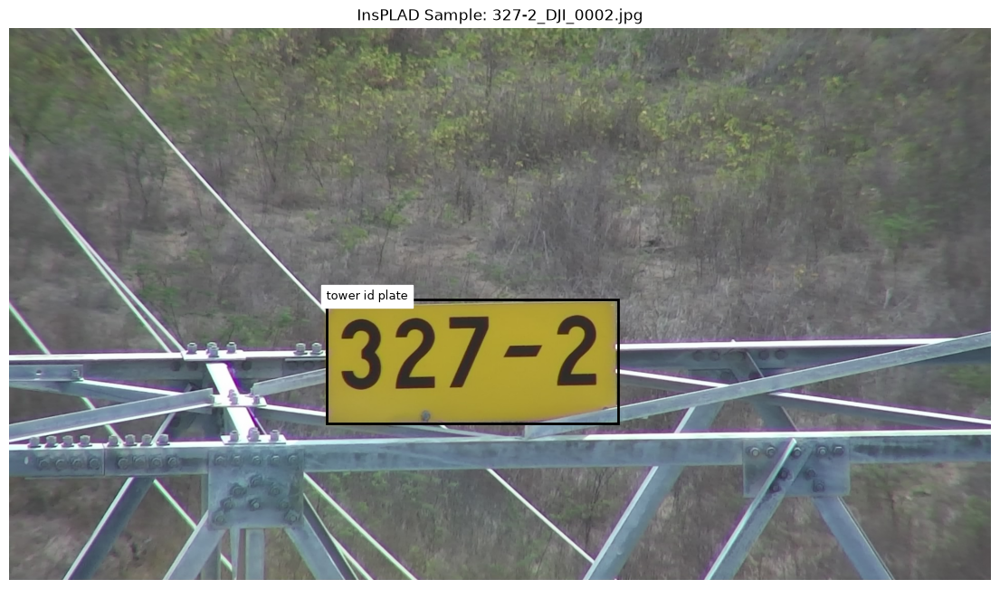

In [7]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

img = Image.open(image_path).convert("RGB")

fig, ax = plt.subplots(figsize=(14, 8))

ax.imshow(img)

for ann in sample_annotations:

    x, y, w, h = ann["bbox"]

    category_id = ann["category_id"]

    category_name = next(
        (
            c["name"]
            for c in categories
            if c["id"] == category_id
        ),
        str(category_id)
    )

    rect = patches.Rectangle(
        (x, y),
        w,
        h,
        linewidth=2,
        fill=False
    )

    ax.add_patch(rect)

    ax.text(
        x,
        y,
        category_name,
        fontsize=9,
        backgroundcolor="white"
    )

ax.set_title(f"InsPLAD Sample: {file_name}")
ax.axis("off")

plt.show()

In [8]:
# ============================================================
# COCO → FASTER R-CNN BOX FORMAT
# ============================================================

ann = sample_annotations[0]

x, y, width, height = ann["bbox"]

x_min = x
y_min = y
x_max = x + width
y_max = y + height

print("=" * 60)
print("BOUNDING BOX CONVERSION")
print("=" * 60)

print("Original COCO format:")
print("[x, y, width, height]")
print(ann["bbox"])

print("\nFaster R-CNN format:")
print("[x_min, y_min, x_max, y_max]")
print([
    x_min,
    y_min,
    x_max,
    y_max
])

print("\nClass ID:", ann["category_id"])
print("Class name:", next(
    c["name"]
    for c in categories
    if c["id"] == ann["category_id"]
))

BOUNDING BOX CONVERSION
Original COCO format:
[x, y, width, height]
[620, 531, 570, 243]

Faster R-CNN format:
[x_min, y_min, x_max, y_max]
[620, 531, 1190, 774]

Class ID: 9
Class name: tower id plate


In [9]:
import torch
from torch.utils.data import Dataset
from PIL import Image

class InsPLADDataset(Dataset):

    def __init__(
        self,
        image_dir,
        annotation_file,
        transforms=None
    ):
        
        self.image_dir = image_dir
        self.transforms = transforms

        # Load COCO JSON
        with open(annotation_file, "r") as f:
            self.coco = json.load(f)

        # Images
        self.images = self.coco["images"]

        # Annotations
        self.annotations = self.coco["annotations"]

        # Categories
        self.categories = self.coco["categories"]

        # Map image_id → annotations
        self.image_annotations = {}

        for ann in self.annotations:

            image_id = ann["image_id"]

            if image_id not in self.image_annotations:
                self.image_annotations[image_id] = []

            self.image_annotations[image_id].append(ann)

        print(
            f"Loaded {len(self.images)} images "
            f"from {annotation_file}"
        )

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        # ----------------------------------------------------
        # IMAGE INFORMATION
        # ----------------------------------------------------

        image_info = self.images[idx]

        image_id = image_info["id"]
        file_name = image_info["file_name"]

        image_path = os.path.join(
            self.image_dir,
            file_name
        )

        # ----------------------------------------------------
        # LOAD IMAGE
        # ----------------------------------------------------

        image = Image.open(
            image_path
        ).convert("RGB")

        # ----------------------------------------------------
        # GET ANNOTATIONS
        # ----------------------------------------------------

        annotations = self.image_annotations.get(
            image_id,
            []
        )

        boxes = []
        labels = []
        areas = []
        iscrowd = []

        # ----------------------------------------------------
        # CONVERT COCO BOXES
        # ----------------------------------------------------

        for ann in annotations:

            x, y, width, height = ann["bbox"]

            x_min = x
            y_min = y

            x_max = x + width
            y_max = y + height

            # Ignore invalid boxes
            if x_max <= x_min or y_max <= y_min:
                continue

            boxes.append([
                x_min,
                y_min,
                x_max,
                y_max
            ])

            labels.append(
                ann["category_id"]
            )

            areas.append(
                ann.get(
                    "area",
                    width * height
                )
            )

            iscrowd.append(
                ann.get("iscrowd", 0)
            )

        # ----------------------------------------------------
        # CONVERT TO TENSORS
        # ----------------------------------------------------

        boxes = torch.as_tensor(
            boxes,
            dtype=torch.float32
        )

        labels = torch.as_tensor(
            labels,
            dtype=torch.int64
        )

        areas = torch.as_tensor(
            areas,
            dtype=torch.float32
        )

        iscrowd = torch.as_tensor(
            iscrowd,
            dtype=torch.int64
        )

        # ----------------------------------------------------
        # TARGET DICTIONARY
        # ----------------------------------------------------

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor(
                [image_id]
            ),
            "area": areas,
            "iscrowd": iscrowd
        }

        # ----------------------------------------------------
        # TRANSFORMS
        # ----------------------------------------------------

        if self.transforms is not None:
            image = self.transforms(image)

        else:
            # PIL → Tensor
            image = torch.from_numpy(
                np.array(image)
            ).permute(2, 0, 1).float() / 255.0

        return image, target

In [10]:
train_dataset = InsPLADDataset(
    image_dir=TRAIN_DIR,
    annotation_file=TRAIN_ANNOTATION
)

print("\nTraining dataset size:", len(train_dataset))

Loaded 7981 images from D:\python\InsPLAD\InsPLAD-det\annotations\instances_train.json

Training dataset size: 7981


In [11]:
val_dataset = InsPLADDataset(
    image_dir=VAL_DIR,
    annotation_file=VAL_ANNOTATION
)

print("\nValidation dataset size:", len(val_dataset))

Loaded 2626 images from D:\python\InsPLAD\InsPLAD-det\annotations\instances_val.json

Validation dataset size: 2626


In [13]:
import numpy as np

print("NumPy:", np.__version__)

NumPy: 2.5.2


In [14]:
image, target = train_dataset[0]

print("=" * 60)
print("DATASET SAMPLE TEST")
print("=" * 60)

print("Image shape :", image.shape)
print("Image dtype :", image.dtype)

print("\nBoxes shape :", target["boxes"].shape)
print("Boxes:")
print(target["boxes"])

print("\nLabels shape:", target["labels"].shape)
print("Labels:")
print(target["labels"])

print("\nImage ID:")
print(target["image_id"])

print("\nArea:")
print(target["area"])

DATASET SAMPLE TEST
Image shape : torch.Size([3, 1080, 1920])
Image dtype : torch.float32

Boxes shape : torch.Size([1, 4])
Boxes:
tensor([[ 620.,  531., 1190.,  774.]])

Labels shape: torch.Size([1])
Labels:
tensor([9])

Image ID:
tensor([0])

Area:
tensor([138510.])


In [15]:
print("=" * 60)
print("TESTING MULTIPLE DATASET SAMPLES")
print("=" * 60)

test_indices = [0, 10, 50, 100, 500, 1000]

for idx in test_indices:

    image, target = train_dataset[idx]

    print(
        f"\nIndex: {idx}"
    )

    print(
        "  Image shape :",
        tuple(image.shape)
    )

    print(
        "  Boxes shape :",
        tuple(target["boxes"].shape)
    )

    print(
        "  Number boxes:",
        len(target["boxes"])
    )

    print(
        "  Labels      :",
        target["labels"].tolist()
    )

    # Verify box shape
    if target["boxes"].ndim != 2:
        print("  ❌ ERROR: boxes must be 2-dimensional")

    elif target["boxes"].shape[1] != 4:
        print("  ❌ ERROR: boxes must have 4 coordinates")

    else:
        print("  ✅ Box format correct")

TESTING MULTIPLE DATASET SAMPLES

Index: 0
  Image shape : (3, 1080, 1920)
  Boxes shape : (1, 4)
  Number boxes: 1
  Labels      : [9]
  ✅ Box format correct

Index: 10
  Image shape : (3, 1080, 1920)
  Boxes shape : (12, 4)
  Number boxes: 12
  Labels      : [1, 4, 4, 4, 4, 4, 4, 4, 2, 2, 2, 11]
  ✅ Box format correct

Index: 50
  Image shape : (3, 1080, 1920)
  Boxes shape : (1, 4)
  Number boxes: 1
  Labels      : [6]
  ✅ Box format correct

Index: 100
  Image shape : (3, 1080, 1920)
  Boxes shape : (1, 4)
  Number boxes: 1
  Labels      : [12]
  ✅ Box format correct

Index: 500
  Image shape : (3, 1080, 1920)
  Boxes shape : (3, 4)
  Number boxes: 3
  Labels      : [8, 11, 2]
  ✅ Box format correct

Index: 1000
  Image shape : (3, 1080, 1920)
  Boxes shape : (1, 4)
  Number boxes: 1
  Labels      : [8]
  ✅ Box format correct


In [17]:
from tqdm.auto import tqdm

print("✅ tqdm imported successfully")

✅ tqdm imported successfully


C:\Users\pabit\dlproject_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [18]:
print("=" * 60)
print("CHECKING TRAINING DATASET")
print("=" * 60)

invalid_images = []
empty_images = 0
total_boxes = 0

for idx in tqdm(
    range(len(train_dataset)),
    desc="Checking training dataset"
):

    image, target = train_dataset[idx]

    boxes = target["boxes"]

    # Empty boxes
    if len(boxes) == 0:
        empty_images += 1

    # Wrong tensor shape
    if boxes.ndim != 2 or boxes.shape[1] != 4:

        invalid_images.append({
            "index": idx,
            "shape": tuple(boxes.shape)
        })
        continue

    # Invalid coordinates
    if len(boxes) > 0:

        x_min = boxes[:, 0]
        y_min = boxes[:, 1]
        x_max = boxes[:, 2]
        y_max = boxes[:, 3]

        invalid = (
            (x_max <= x_min) |
            (y_max <= y_min)
        )

        if invalid.any():

            invalid_images.append({
                "index": idx,
                "shape": tuple(boxes.shape),
                "invalid_boxes": int(invalid.sum())
            })

    total_boxes += len(boxes)


print("\n" + "=" * 60)
print("TRAINING DATASET RESULT")
print("=" * 60)

print("Total images       :", len(train_dataset))
print("Total valid boxes  :", total_boxes)
print("Images with no box :", empty_images)
print("Invalid images     :", len(invalid_images))

if len(invalid_images) == 0:
    print("\n✅ NO INVALID BOUNDING BOXES FOUND")
else:
    print("\n⚠️ INVALID DATA FOUND")

    print("\nFirst problematic samples:")

    for item in invalid_images[:10]:
        print(item)

CHECKING TRAINING DATASET


Checking training dataset: 100%|██████████| 7981/7981 [09:16<00:00, 14.34it/s]


TRAINING DATASET RESULT
Total images       : 7981
Total valid boxes  : 22635
Images with no box : 2
Invalid images     : 2

⚠️ INVALID DATA FOUND

First problematic samples:
{'index': 4785, 'shape': (0,)}
{'index': 4786, 'shape': (0,)}


In [19]:
print("=" * 60)
print("CHECKING VALIDATION DATASET")
print("=" * 60)

invalid_val = []
empty_val = 0
total_val_boxes = 0

for idx in tqdm(
    range(len(val_dataset)),
    desc="Checking validation dataset"
):

    image, target = val_dataset[idx]

    boxes = target["boxes"]

    if len(boxes) == 0:
        empty_val += 1

    if boxes.ndim != 2 or boxes.shape[1] != 4:

        invalid_val.append({
            "index": idx,
            "shape": tuple(boxes.shape)
        })
        continue

    if len(boxes) > 0:

        x_min = boxes[:, 0]
        y_min = boxes[:, 1]
        x_max = boxes[:, 2]
        y_max = boxes[:, 3]

        invalid = (
            (x_max <= x_min) |
            (y_max <= y_min)
        )

        if invalid.any():

            invalid_val.append({
                "index": idx,
                "shape": tuple(boxes.shape),
                "invalid_boxes": int(invalid.sum())
            })

    total_val_boxes += len(boxes)


print("\n" + "=" * 60)
print("VALIDATION DATASET RESULT")
print("=" * 60)

print("Total images       :", len(val_dataset))
print("Total valid boxes  :", total_val_boxes)
print("Images with no box :", empty_val)
print("Invalid images     :", len(invalid_val))

if len(invalid_val) == 0:
    print("\n✅ NO INVALID VALIDATION BOXES FOUND")
else:
    print("\n⚠️ INVALID VALIDATION DATA FOUND")

    for item in invalid_val[:10]:
        print(item)

CHECKING VALIDATION DATASET


Checking validation dataset: 100%|██████████| 2626/2626 [03:35<00:00, 12.21it/s]


VALIDATION DATASET RESULT
Total images       : 2626
Total valid boxes  : 6324
Images with no box : 0
Invalid images     : 0

✅ NO INVALID VALIDATION BOXES FOUND


In [20]:
class InsPLADDataset(Dataset):

    def __init__(
        self,
        image_dir,
        annotation_file,
        transforms=None
    ):

        self.image_dir = image_dir
        self.transforms = transforms

        # Load COCO JSON
        with open(annotation_file, "r") as f:
            self.coco = json.load(f)

        self.images = self.coco["images"]
        self.annotations = self.coco["annotations"]
        self.categories = self.coco["categories"]

        # Map image_id -> annotations
        self.image_annotations = {}

        for ann in self.annotations:

            image_id = ann["image_id"]

            if image_id not in self.image_annotations:
                self.image_annotations[image_id] = []

            self.image_annotations[image_id].append(ann)

        print(
            f"Loaded {len(self.images)} images "
            f"from {annotation_file}"
        )

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        # --------------------------------------------------
        # IMAGE INFORMATION
        # --------------------------------------------------

        image_info = self.images[idx]

        image_id = image_info["id"]
        file_name = image_info["file_name"]

        image_path = os.path.join(
            self.image_dir,
            file_name
        )

        # --------------------------------------------------
        # LOAD IMAGE
        # --------------------------------------------------

        image = Image.open(
            image_path
        ).convert("RGB")

        # --------------------------------------------------
        # GET ANNOTATIONS
        # --------------------------------------------------

        annotations = self.image_annotations.get(
            image_id,
            []
        )

        boxes = []
        labels = []
        areas = []
        iscrowd = []

        # --------------------------------------------------
        # CONVERT COCO BOXES
        # --------------------------------------------------

        for ann in annotations:

            x, y, width, height = ann["bbox"]

            x_min = x
            y_min = y
            x_max = x + width
            y_max = y + height

            # Skip invalid boxes
            if x_max <= x_min or y_max <= y_min:
                continue

            boxes.append([
                x_min,
                y_min,
                x_max,
                y_max
            ])

            labels.append(
                ann["category_id"]
            )

            areas.append(
                ann.get(
                    "area",
                    width * height
                )
            )

            iscrowd.append(
                ann.get("iscrowd", 0)
            )

        # --------------------------------------------------
        # CONVERT BOXES
        # IMPORTANT: empty boxes become [0, 4]
        # --------------------------------------------------

        if len(boxes) == 0:

            boxes = torch.zeros(
                (0, 4),
                dtype=torch.float32
            )

        else:

            boxes = torch.as_tensor(
                boxes,
                dtype=torch.float32
            )

        # --------------------------------------------------
        # LABELS
        # --------------------------------------------------

        labels = torch.as_tensor(
            labels,
            dtype=torch.int64
        )

        # --------------------------------------------------
        # AREAS
        # --------------------------------------------------

        areas = torch.as_tensor(
            areas,
            dtype=torch.float32
        )

        # --------------------------------------------------
        # IS-CROWD
        # --------------------------------------------------

        iscrowd = torch.as_tensor(
            iscrowd,
            dtype=torch.int64
        )

        # --------------------------------------------------
        # TARGET
        # --------------------------------------------------

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor(
                [image_id],
                dtype=torch.int64
            ),
            "area": areas,
            "iscrowd": iscrowd
        }

        # --------------------------------------------------
        # TRANSFORM
        # --------------------------------------------------

        if self.transforms is not None:

            image = self.transforms(image)

        else:

            image = torch.from_numpy(
                np.array(image)
            ).permute(
                2, 0, 1
            ).float() / 255.0

        return image, target

In [21]:
train_dataset = InsPLADDataset(
    image_dir=TRAIN_DIR,
    annotation_file=TRAIN_ANNOTATION
)

val_dataset = InsPLADDataset(
    image_dir=VAL_DIR,
    annotation_file=VAL_ANNOTATION
)

print("\n" + "=" * 60)
print("DATASETS READY")
print("=" * 60)

print("Training images  :", len(train_dataset))
print("Validation images:", len(val_dataset))

Loaded 7981 images from D:\python\InsPLAD\InsPLAD-det\annotations\instances_train.json
Loaded 2626 images from D:\python\InsPLAD\InsPLAD-det\annotations\instances_val.json

DATASETS READY
Training images  : 7981
Validation images: 2626


In [22]:
print("=" * 60)
print("TESTING PREVIOUSLY PROBLEMATIC IMAGES")
print("=" * 60)

for idx in [4785, 4786]:

    image, target = train_dataset[idx]

    print(f"\nIndex: {idx}")

    print("Image shape :", image.shape)
    print("Boxes shape :", target["boxes"].shape)
    print("Labels shape:", target["labels"].shape)

    print("Boxes:")
    print(target["boxes"])

    print("Labels:")
    print(target["labels"])

    # Assertions
    assert target["boxes"].ndim == 2
    assert target["boxes"].shape[1] == 4

    print("✅ This sample is now valid for Faster R-CNN")

TESTING PREVIOUSLY PROBLEMATIC IMAGES

Index: 4785
Image shape : torch.Size([3, 1080, 1920])
Boxes shape : torch.Size([0, 4])
Labels shape: torch.Size([0])
Boxes:
tensor([], size=(0, 4))
Labels:
tensor([], dtype=torch.int64)
✅ This sample is now valid for Faster R-CNN

Index: 4786
Image shape : torch.Size([3, 1080, 1920])
Boxes shape : torch.Size([0, 4])
Labels shape: torch.Size([0])
Boxes:
tensor([], size=(0, 4))
Labels:
tensor([], dtype=torch.int64)
✅ This sample is now valid for Faster R-CNN


In [23]:
test_indices = [
    0,
    10,
    100,
    4785,
    4786,
    5000,
    7000
]

print("=" * 60)
print("FINAL DATASET FORMAT CHECK")
print("=" * 60)

for idx in test_indices:

    image, target = train_dataset[idx]

    boxes = target["boxes"]
    labels = target["labels"]

    print(
        f"\nIndex {idx}"
        f"\n  Image : {tuple(image.shape)}"
        f"\n  Boxes : {tuple(boxes.shape)}"
        f"\n  Labels: {tuple(labels.shape)}"
    )

    assert boxes.ndim == 2
    assert boxes.shape[1] == 4

    assert labels.ndim == 1

    assert len(boxes) == len(labels)

    print("  ✅ VALID")

FINAL DATASET FORMAT CHECK

Index 0
  Image : (3, 1080, 1920)
  Boxes : (1, 4)
  Labels: (1,)
  ✅ VALID

Index 10
  Image : (3, 1080, 1920)
  Boxes : (12, 4)
  Labels: (12,)
  ✅ VALID

Index 100
  Image : (3, 1080, 1920)
  Boxes : (1, 4)
  Labels: (1,)
  ✅ VALID

Index 4785
  Image : (3, 1080, 1920)
  Boxes : (0, 4)
  Labels: (0,)
  ✅ VALID

Index 4786
  Image : (3, 1080, 1920)
  Boxes : (0, 4)
  Labels: (0,)
  ✅ VALID

Index 5000
  Image : (3, 1080, 1920)
  Boxes : (12, 4)
  Labels: (12,)
  ✅ VALID

Index 7000
  Image : (3, 1080, 1920)
  Boxes : (2, 4)
  Labels: (2,)
  ✅ VALID


In [24]:
from torch.utils.data import DataLoader

# Custom collate function for object detection
def collate_fn(batch):
    return tuple(zip(*batch))


# Create training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=1,          # Important: RTX 2050 has only 4 GB VRAM
    shuffle=True,
    num_workers=0,         # Safer for Windows + Jupyter
    collate_fn=collate_fn,
    pin_memory=True
)


# Create validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn,
    pin_memory=True
)

print("=" * 60)
print("DATALOADER CREATED SUCCESSFULLY")
print("=" * 60)

print("Training images     :", len(train_dataset))
print("Validation images   :", len(val_dataset))
print("Training batches    :", len(train_loader))
print("Validation batches  :", len(val_loader))
print("Batch size          :", train_loader.batch_size)

DATALOADER CREATED SUCCESSFULLY
Training images     : 7981
Validation images   : 2626
Training batches    : 7981
Validation batches  : 2626
Batch size          : 1


In [25]:
print("=" * 60)
print("TESTING TRAIN DATALOADER")
print("=" * 60)

images, targets = next(iter(train_loader))

print("Number of images :", len(images))
print("Number of targets:", len(targets))

print("\nImage shape:")
print(images[0].shape)

print("\nTarget keys:")
print(targets[0].keys())

print("\nBoxes shape:")
print(targets[0]["boxes"].shape)

print("\nLabels shape:")
print(targets[0]["labels"].shape)

print("\nImage ID:")
print(targets[0]["image_id"])

print("\n✅ DATALOADER TEST PASSED")

TESTING TRAIN DATALOADER
Number of images : 1
Number of targets: 1

Image shape:
torch.Size([3, 1080, 1920])

Target keys:
dict_keys(['boxes', 'labels', 'image_id', 'area', 'iscrowd'])

Boxes shape:
torch.Size([1, 4])

Labels shape:
torch.Size([1])

Image ID:
tensor([2286])

✅ DATALOADER TEST PASSED


In [26]:
import torch
import torchvision

from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)

from torchvision.models.detection.faster_rcnn import FastRCNNPredictor


print("=" * 60)
print("CREATING FASTER R-CNN MODEL")
print("=" * 60)

# Number of classes
# 18 dataset classes + 1 background class
num_classes = 19

print("Number of classes:", num_classes)

# Load Faster R-CNN with pretrained COCO weights
weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT

model = fasterrcnn_resnet50_fpn(
    weights=weights
)

# Get the number of input features of the existing classifier
in_features = model.roi_heads.box_predictor.cls_score.in_features

# Replace the COCO classifier with our 19-class classifier
model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes
)

print("\nModel created successfully!")
print("Backbone          : ResNet-50 + FPN")
print("Detection model   : Faster R-CNN")
print("Number of classes :", num_classes)
print("Classifier input  :", in_features)

print("\n✅ FASTER R-CNN MODEL READY")

CREATING FASTER R-CNN MODEL
Number of classes: 19
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to C:\Users\pabit/.cache\torch\hub\checkpoints\fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:41<00:00, 4.07MB/s] 



Model created successfully!
Backbone          : ResNet-50 + FPN
Detection model   : Faster R-CNN
Number of classes : 19
Classifier input  : 1024

✅ FASTER R-CNN MODEL READY


In [27]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 60)
print("DEVICE CONFIGURATION")
print("=" * 60)

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(torch.cuda.get_device_properties(0).total_memory / (1024**3), 2),
        "GB"
    )

model = model.to(device)

print("\n✅ MODEL MOVED TO DEVICE")

DEVICE CONFIGURATION
Device: cuda
GPU: NVIDIA GeForce RTX 2050
GPU Memory: 4.0 GB

✅ MODEL MOVED TO DEVICE


In [28]:
print("=" * 60)
print("STEP 32 — FASTER R-CNN SINGLE-BATCH TEST")
print("=" * 60)

# Get one batch
images, targets = next(iter(train_loader))

# Move images and targets to GPU
images = [img.to(device) for img in images]

targets = [
    {
        key: value.to(device) if torch.is_tensor(value) else value
        for key, value in target.items()
    }
    for target in targets
]

print("Number of images :", len(images))
print("Image shape      :", images[0].shape)
print("Boxes shape      :", targets[0]["boxes"].shape)
print("Labels shape     :", targets[0]["labels"].shape)

# Training mode
model.train()

# Forward pass
with torch.no_grad():
    loss_dict = model(images, targets)

print("\nLoss components:")

for name, loss in loss_dict.items():
    print(f"{name:25s}: {loss.item():.6f}")

total_loss = sum(loss for loss in loss_dict.values())

print("\nTotal loss:", total_loss.item())

print("\n✅ SINGLE-BATCH FORWARD TEST PASSED")

STEP 32 — FASTER R-CNN SINGLE-BATCH TEST
Number of images : 1
Image shape      : torch.Size([3, 1080, 1920])
Boxes shape      : torch.Size([2, 4])
Labels shape     : torch.Size([2])

Loss components:
loss_classifier          : 2.952026
loss_box_reg             : 0.304779
loss_objectness          : 0.016877
loss_rpn_box_reg         : 0.004348

Total loss: 3.278028964996338

✅ SINGLE-BATCH FORWARD TEST PASSED


In [29]:
print("=" * 60)
print("STEP 33 — TESTING EMPTY-ANNOTATION IMAGES")
print("=" * 60)

model.train()

empty_indices = [4785, 4786]

for idx in empty_indices:

    print(f"\nTesting dataset index: {idx}")

    # Get image and target
    image, target = train_dataset[idx]

    print("Image shape :", image.shape)
    print("Boxes shape :", target["boxes"].shape)
    print("Labels shape:", target["labels"].shape)

    # Move image to GPU
    images = [image.to(device)]

    # Move target tensors to GPU
    targets = [
        {
            key: value.to(device) if torch.is_tensor(value) else value
            for key, value in target.items()
        }
    ]

    # Forward pass
    with torch.no_grad():
        loss_dict = model(images, targets)

    # Calculate total loss
    total_loss = sum(loss for loss in loss_dict.values())

    print("Loss components:")

    for name, loss in loss_dict.items():
        print(f"  {name:23s}: {loss.item():.6f}")

    print(f"  {'Total loss':23s}: {total_loss.item():.6f}")

    print("✅ Image processed successfully")

print("\n" + "=" * 60)
print("EMPTY-IMAGE TEST COMPLETED")
print("=" * 60)

STEP 33 — TESTING EMPTY-ANNOTATION IMAGES

Testing dataset index: 4785
Image shape : torch.Size([3, 1080, 1920])
Boxes shape : torch.Size([0, 4])
Labels shape: torch.Size([0])
Loss components:
  loss_classifier        : 2.904459
  loss_box_reg           : 0.000000
  loss_objectness        : 0.001839
  loss_rpn_box_reg       : 0.000000
  Total loss             : 2.906297
✅ Image processed successfully

Testing dataset index: 4786
Image shape : torch.Size([3, 1080, 1920])
Boxes shape : torch.Size([0, 4])
Labels shape: torch.Size([0])
Loss components:
  loss_classifier        : 2.874064
  loss_box_reg           : 0.000000
  loss_objectness        : 0.014555
  loss_rpn_box_reg       : 0.000000
  Total loss             : 2.888619
✅ Image processed successfully

EMPTY-IMAGE TEST COMPLETED


In [30]:
import torch

print("=" * 60)
print("STEP 34 — TRAINING CONFIGURATION")
print("=" * 60)

# ---------------------------------------------------------
# DEVICE
# ---------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ---------------------------------------------------------
# TRAINING PARAMETERS
# ---------------------------------------------------------

NUM_EPOCHS = 10

LEARNING_RATE = 0.0001

WEIGHT_DECAY = 0.0005

# Batch size is already 1 because of the 4 GB GPU
BATCH_SIZE = 1

# ---------------------------------------------------------
# OPTIMIZER
# ---------------------------------------------------------

params = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]

optimizer = torch.optim.AdamW(
    params,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ---------------------------------------------------------
# LEARNING RATE SCHEDULER
# ---------------------------------------------------------

lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

# ---------------------------------------------------------
# MIXED PRECISION
# ---------------------------------------------------------

AMP_ENABLED = device.type == "cuda"

print("Device           :", device)
print("Epochs           :", NUM_EPOCHS)
print("Batch size       :", BATCH_SIZE)
print("Learning rate    :", LEARNING_RATE)
print("Weight decay     :", WEIGHT_DECAY)
print("Optimizer        : AdamW")
print("LR scheduler     : StepLR")
print("AMP enabled      :", AMP_ENABLED)

if device.type == "cuda":
    print("GPU              :", torch.cuda.get_device_name(0))

print("\n✅ TRAINING CONFIGURATION READY")

STEP 34 — TRAINING CONFIGURATION
Device           : cuda
Epochs           : 10
Batch size       : 1
Learning rate    : 0.0001
Weight decay     : 0.0005
Optimizer        : AdamW
LR scheduler     : StepLR
AMP enabled      : True
GPU              : NVIDIA GeForce RTX 2050

✅ TRAINING CONFIGURATION READY


In [31]:
import os
import torch

# ============================================================
# STEP 35 — CHECKPOINT & RESUME SYSTEM
# ============================================================

CHECKPOINT_DIR = r"D:\python\DLproject_checkpoints"

# Create checkpoint directory if it does not exist
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("=" * 60)
print("STEP 35 — CHECKPOINT SYSTEM")
print("=" * 60)

print("Checkpoint directory:")
print(CHECKPOINT_DIR)

print("\nDirectory exists:", os.path.exists(CHECKPOINT_DIR))

# ------------------------------------------------------------
# Function to save checkpoint
# ------------------------------------------------------------

def save_checkpoint(
    epoch,
    model,
    optimizer,
    scheduler,
    loss,
    filename
):
    
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "loss": loss
    }
    
    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        filename
    )
    
    torch.save(
        checkpoint,
        checkpoint_path
    )
    
    print(f"✅ Checkpoint saved: {checkpoint_path}")


# ------------------------------------------------------------
# Function to load checkpoint
# ------------------------------------------------------------

def load_checkpoint(
    checkpoint_path,
    model,
    optimizer,
    scheduler,
    device
):
    
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device
    )
    
    model.load_state_dict(
        checkpoint["model_state_dict"]
    )
    
    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )
    
    scheduler.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )
    
    start_epoch = checkpoint["epoch"] + 1
    
    loss = checkpoint.get("loss", None)
    
    print("✅ Checkpoint loaded successfully")
    print("Last completed epoch :", checkpoint["epoch"])
    print("Next epoch           :", start_epoch)
    print("Previous loss        :", loss)
    
    return start_epoch


print("\n✅ CHECKPOINT FUNCTIONS READY")

STEP 35 — CHECKPOINT SYSTEM
Checkpoint directory:
D:\python\DLproject_checkpoints

Directory exists: True

✅ CHECKPOINT FUNCTIONS READY


In [32]:
import os

print("=" * 60)
print("CHECKPOINT DIRECTORY CHECK")
print("=" * 60)

files = os.listdir(CHECKPOINT_DIR)

if len(files) == 0:
    print("Checkpoint folder is currently empty.")
else:
    print("Existing checkpoint files:")
    for file in files:
        print(" -", file)

CHECKPOINT DIRECTORY CHECK
Checkpoint folder is currently empty.


In [33]:
# ============================================================
# STEP 36 — TRAINING SMOKE TEST
# ============================================================

import torch

print("=" * 60)
print("STEP 36 — TRAINING SMOKE TEST")
print("=" * 60)

model.train()

smoke_test_batches = 5

smoke_losses = []

for batch_idx, (images, targets) in enumerate(train_loader):

    if batch_idx >= smoke_test_batches:
        break

    print(f"\nBatch {batch_idx + 1}/{smoke_test_batches}")

    # --------------------------------------------------------
    # Move images to GPU
    # --------------------------------------------------------

    images = [
        image.to(device, non_blocking=True)
        for image in images
    ]

    # --------------------------------------------------------
    # Move target tensors to GPU
    # --------------------------------------------------------

    targets = [
        {
            key: value.to(device, non_blocking=True)
            if torch.is_tensor(value)
            else value
            for key, value in target.items()
        }
        for target in targets
    ]

    # --------------------------------------------------------
    # Clear previous gradients
    # --------------------------------------------------------

    optimizer.zero_grad(set_to_none=True)

    # --------------------------------------------------------
    # Forward + loss calculation
    # --------------------------------------------------------

    with torch.amp.autocast(
        device_type="cuda",
        enabled=AMP_ENABLED
    ):
        loss_dict = model(
            images,
            targets
        )

        total_loss = sum(
            loss for loss in loss_dict.values()
        )

    # --------------------------------------------------------
    # Backward pass
    # --------------------------------------------------------

    total_loss.backward()

    # --------------------------------------------------------
    # Optimizer update
    # --------------------------------------------------------

    optimizer.step()

    loss_value = total_loss.item()

    smoke_losses.append(loss_value)

    print(f"Loss: {loss_value:.6f}")

    # --------------------------------------------------------
    # GPU memory information
    # --------------------------------------------------------

    if device.type == "cuda":

        allocated = (
            torch.cuda.memory_allocated(device)
            / (1024 ** 3)
        )

        reserved = (
            torch.cuda.memory_reserved(device)
            / (1024 ** 3)
        )

        print(
            f"GPU allocated: {allocated:.2f} GB"
        )

        print(
            f"GPU reserved : {reserved:.2f} GB"
        )


# ------------------------------------------------------------
# Smoke test summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SMOKE TEST SUMMARY")
print("=" * 60)

print("Batches completed:", len(smoke_losses))

if smoke_losses:
    print(
        "First loss       :",
        f"{smoke_losses[0]:.6f}"
    )

    print(
        "Last loss        :",
        f"{smoke_losses[-1]:.6f}"
    )

print("\n✅ TRAINING SMOKE TEST COMPLETED")

STEP 36 — TRAINING SMOKE TEST

Batch 1/5
Loss: 3.196964
GPU allocated: 0.67 GB
GPU reserved : 1.56 GB

Batch 2/5
Loss: 1.657618
GPU allocated: 0.67 GB
GPU reserved : 1.82 GB

Batch 3/5
Loss: 1.586533
GPU allocated: 0.67 GB
GPU reserved : 1.82 GB

Batch 4/5
Loss: 0.256325
GPU allocated: 0.67 GB
GPU reserved : 1.82 GB

Batch 5/5
Loss: 0.302188
GPU allocated: 0.67 GB
GPU reserved : 1.82 GB

SMOKE TEST SUMMARY
Batches completed: 5
First loss       : 3.196964
Last loss        : 0.302188

✅ TRAINING SMOKE TEST COMPLETED


In [34]:
# ============================================================
# STEP 37 — PREPARE CLEAN MODEL FOR OFFICIAL TRAINING
# ============================================================

import torch

print("=" * 60)
print("STEP 37 — PREPARING CLEAN TRAINING MODEL")
print("=" * 60)

# ------------------------------------------------------------
# Recreate Faster R-CNN from pretrained COCO weights
# ------------------------------------------------------------

weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT

model = fasterrcnn_resnet50_fpn(
    weights=weights
)

# Number of input features for the classifier
in_features = model.roi_heads.box_predictor.cls_score.in_features

# Replace COCO predictor with our 19-class predictor
model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes
)

# ------------------------------------------------------------
# Move model to GPU
# ------------------------------------------------------------

model = model.to(device)

# ------------------------------------------------------------
# Create optimizer again
# ------------------------------------------------------------

params = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]

optimizer = torch.optim.AdamW(
    params,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ------------------------------------------------------------
# Create scheduler again
# ------------------------------------------------------------

lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

# ------------------------------------------------------------
# Official training start
# ------------------------------------------------------------

START_EPOCH = 1

print("Model              : Faster R-CNN ResNet-50 FPN")
print("Classes            :", num_classes)
print("Device             :", device)
print("Starting epoch     :", START_EPOCH)
print("Learning rate      :", LEARNING_RATE)
print("Weight decay       :", WEIGHT_DECAY)
print("Optimizer          : AdamW")
print("Scheduler          : StepLR")
print("AMP enabled        :", AMP_ENABLED)

print("\n✅ CLEAN MODEL READY FOR OFFICIAL TRAINING")

STEP 37 — PREPARING CLEAN TRAINING MODEL
Model              : Faster R-CNN ResNet-50 FPN
Classes            : 19
Device             : cuda
Starting epoch     : 1
Learning rate      : 0.0001
Weight decay       : 0.0005
Optimizer          : AdamW
Scheduler          : StepLR
AMP enabled        : True

✅ CLEAN MODEL READY FOR OFFICIAL TRAINING


In [2]:
# ============================================================
# STEP 38A — RESTORE TRAINING START
# ============================================================

START_EPOCH = 1

print("=" * 60)
print("TRAINING START CONFIGURATION")
print("=" * 60)

print("START_EPOCH:", START_EPOCH)

print("\n✅ START_EPOCH restored")

TRAINING START CONFIGURATION
START_EPOCH: 1

✅ START_EPOCH restored


In [3]:
# ============================================================
# STEP 38B — CHECK TRAINING VARIABLES
# ============================================================

print("=" * 60)
print("CHECKING TRAINING VARIABLES")
print("=" * 60)

variables_to_check = [
    "model",
    "train_loader",
    "optimizer",
    "lr_scheduler",
    "NUM_EPOCHS",
    "device",
    "AMP_ENABLED",
    "save_checkpoint"
]

for name in variables_to_check:

    if name in globals():
        print(f"✅ {name}")
    else:
        print(f"❌ {name} — NOT DEFINED")

CHECKING TRAINING VARIABLES
❌ model — NOT DEFINED
❌ train_loader — NOT DEFINED
❌ optimizer — NOT DEFINED
❌ lr_scheduler — NOT DEFINED
❌ NUM_EPOCHS — NOT DEFINED
❌ device — NOT DEFINED
❌ AMP_ENABLED — NOT DEFINED
❌ save_checkpoint — NOT DEFINED


In [4]:
# ============================================================
# STEP 38C — CHECK DATASET OBJECTS
# ============================================================

print("=" * 60)
print("CHECKING DATASET OBJECTS")
print("=" * 60)

dataset_variables = [
    "DATA_DIR",
    "TRAIN_DIR",
    "VAL_DIR",
    "ANNOTATION_DIR",
    "TRAIN_ANNOTATION",
    "VAL_ANNOTATION",
    "CHECKPOINT_DIR",
    "InsPLADDataset",
    "train_dataset",
    "val_dataset"
]

for name in dataset_variables:

    if name in globals():
        print(f"✅ {name}")
    else:
        print(f"❌ {name} — NOT DEFINED")

CHECKING DATASET OBJECTS
❌ DATA_DIR — NOT DEFINED
❌ TRAIN_DIR — NOT DEFINED
❌ VAL_DIR — NOT DEFINED
❌ ANNOTATION_DIR — NOT DEFINED
❌ TRAIN_ANNOTATION — NOT DEFINED
❌ VAL_ANNOTATION — NOT DEFINED
❌ CHECKPOINT_DIR — NOT DEFINED
❌ InsPLADDataset — NOT DEFINED
❌ train_dataset — NOT DEFINED
❌ val_dataset — NOT DEFINED


In [5]:
# ============================================================
# STEP 38D — RESTORE DATASET PATHS
# ============================================================

import os

DATA_DIR = r"D:\python\InsPLAD\InsPLAD-det"

TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR = os.path.join(DATA_DIR, "val")

ANNOTATION_DIR = os.path.join(DATA_DIR, "annotations")

TRAIN_ANNOTATION = os.path.join(
    ANNOTATION_DIR,
    "instances_train.json"
)

VAL_ANNOTATION = os.path.join(
    ANNOTATION_DIR,
    "instances_val.json"
)

CHECKPOINT_DIR = r"D:\python\DLproject_checkpoints"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("=" * 60)
print("RESTORING DATASET PATHS")
print("=" * 60)

print("DATA_DIR         :", DATA_DIR)
print("TRAIN_DIR        :", TRAIN_DIR)
print("VAL_DIR          :", VAL_DIR)
print("TRAIN_ANNOTATION :", TRAIN_ANNOTATION)
print("VAL_ANNOTATION   :", VAL_ANNOTATION)
print("CHECKPOINT_DIR   :", CHECKPOINT_DIR)

print("\nChecking paths...")

print(
    "Train folder      :",
    os.path.exists(TRAIN_DIR)
)

print(
    "Validation folder :",
    os.path.exists(VAL_DIR)
)

print(
    "Train annotation :",
    os.path.exists(TRAIN_ANNOTATION)
)

print(
    "Val annotation   :",
    os.path.exists(VAL_ANNOTATION)
)

print("\n✅ DATASET PATHS RESTORED")

RESTORING DATASET PATHS
DATA_DIR         : D:\python\InsPLAD\InsPLAD-det
TRAIN_DIR        : D:\python\InsPLAD\InsPLAD-det\train
VAL_DIR          : D:\python\InsPLAD\InsPLAD-det\val
TRAIN_ANNOTATION : D:\python\InsPLAD\InsPLAD-det\annotations\instances_train.json
VAL_ANNOTATION   : D:\python\InsPLAD\InsPLAD-det\annotations\instances_val.json
CHECKPOINT_DIR   : D:\python\DLproject_checkpoints

Checking paths...
Train folder      : True
Validation folder : True
Train annotation : True
Val annotation   : True

✅ DATASET PATHS RESTORED


In [6]:
# ============================================================
# STEP 38E — RESTORE CORRECTED INSPLAD DATASET CLASS
# ============================================================

import os
import json
import torch
from PIL import Image
from torch.utils.data import Dataset


class InsPLADDataset(Dataset):

    def __init__(
        self,
        image_dir,
        annotation_file,
        transforms=None
    ):

        self.image_dir = image_dir
        self.transforms = transforms

        # Load COCO annotation file
        with open(annotation_file, "r") as f:
            self.coco = json.load(f)

        self.images = self.coco["images"]
        self.annotations = self.coco["annotations"]
        self.categories = self.coco["categories"]

        # ----------------------------------------------------
        # Image ID -> annotations
        # ----------------------------------------------------

        self.image_annotations = {}

        for annotation in self.annotations:

            image_id = annotation["image_id"]

            if image_id not in self.image_annotations:
                self.image_annotations[image_id] = []

            self.image_annotations[image_id].append(annotation)

        # ----------------------------------------------------
        # Category mapping
        # ----------------------------------------------------

        category_ids = sorted(
            category["id"]
            for category in self.categories
        )

        self.category_id_to_label = {
            category_id: index + 1
            for index, category_id in enumerate(category_ids)
        }

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_info = self.images[idx]

        image_id = image_info["id"]
        file_name = image_info["file_name"]

        image_path = os.path.join(
            self.image_dir,
            file_name
        )

        # ----------------------------------------------------
        # Load image
        # ----------------------------------------------------

        image = Image.open(image_path).convert("RGB")

        image_width, image_height = image.size

        # ----------------------------------------------------
        # Get annotations
        # ----------------------------------------------------

        annotations = self.image_annotations.get(
            image_id,
            []
        )

        boxes = []
        labels = []
        areas = []
        iscrowd = []

        for annotation in annotations:

            x, y, width, height = annotation["bbox"]

            # Convert COCO format:
            # [x, y, width, height]
            #
            # to Faster R-CNN format:
            # [xmin, ymin, xmax, ymax]

            xmin = max(0, x)
            ymin = max(0, y)

            xmax = min(
                image_width,
                x + width
            )

            ymax = min(
                image_height,
                y + height
            )

            # Ignore invalid boxes
            if xmax <= xmin or ymax <= ymin:
                continue

            boxes.append([
                xmin,
                ymin,
                xmax,
                ymax
            ])

            category_id = annotation["category_id"]

            labels.append(
                self.category_id_to_label[category_id]
            )

            areas.append(
                (xmax - xmin) * (ymax - ymin)
            )

            iscrowd.append(
                annotation.get("iscrowd", 0)
            )

        # ----------------------------------------------------
        # IMPORTANT EMPTY-BOX FIX
        # ----------------------------------------------------

        if len(boxes) == 0:

            boxes = torch.zeros(
                (0, 4),
                dtype=torch.float32
            )

        else:

            boxes = torch.tensor(
                boxes,
                dtype=torch.float32
            )

        labels = torch.tensor(
            labels,
            dtype=torch.int64
        )

        areas = torch.tensor(
            areas,
            dtype=torch.float32
        )

        iscrowd = torch.tensor(
            iscrowd,
            dtype=torch.int64
        )

        # ----------------------------------------------------
        # Target dictionary
        # ----------------------------------------------------

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor(
                [image_id],
                dtype=torch.int64
            ),
            "area": areas,
            "iscrowd": iscrowd
        }

        # ----------------------------------------------------
        # Convert image to tensor
        # ----------------------------------------------------

        image = torch.from_numpy(
            __import__("numpy").array(image)
        )

        image = image.permute(
            2, 0, 1
        ).float() / 255.0

        # ----------------------------------------------------
        # Optional transforms
        # ----------------------------------------------------

        if self.transforms is not None:
            image, target = self.transforms(
                image,
                target
            )

        return image, target


print("=" * 60)
print("INSPLAD DATASET CLASS RESTORED")
print("=" * 60)

print("Class:", InsPLADDataset)

print("\n✅ DATASET CLASS READY")

INSPLAD DATASET CLASS RESTORED
Class: <class '__main__.InsPLADDataset'>

✅ DATASET CLASS READY


In [7]:
# ============================================================
# STEP 38F — RECREATE TRAIN AND VALIDATION DATASETS
# ============================================================

print("=" * 60)
print("CREATING DATASETS")
print("=" * 60)

train_dataset = InsPLADDataset(
    image_dir=TRAIN_DIR,
    annotation_file=TRAIN_ANNOTATION
)

val_dataset = InsPLADDataset(
    image_dir=VAL_DIR,
    annotation_file=VAL_ANNOTATION
)

print("Training images   :", len(train_dataset))
print("Validation images :", len(val_dataset))

print("\n✅ TRAIN AND VALIDATION DATASETS CREATED")

CREATING DATASETS
Training images   : 7981
Validation images : 2626

✅ TRAIN AND VALIDATION DATASETS CREATED


In [8]:
# ============================================================
# STEP 38G — RECREATE DATALOADERS
# ============================================================

from torch.utils.data import DataLoader


# Custom collate function for Faster R-CNN
def collate_fn(batch):
    return tuple(zip(*batch))


# ------------------------------------------------------------
# Training DataLoader
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    collate_fn=collate_fn,
    pin_memory=True
)


# ------------------------------------------------------------
# Validation DataLoader
# ------------------------------------------------------------

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn,
    pin_memory=True
)


print("=" * 60)
print("DATALOADERS RESTORED")
print("=" * 60)

print("Training images    :", len(train_dataset))
print("Validation images  :", len(val_dataset))

print("Training batches   :", len(train_loader))
print("Validation batches :", len(val_loader))

print("Batch size         :", train_loader.batch_size)
print("Workers            :", train_loader.num_workers)

print("\n✅ DATALOADERS READY")

DATALOADERS RESTORED
Training images    : 7981
Validation images  : 2626
Training batches   : 7981
Validation batches : 2626
Batch size         : 1
Workers            : 0

✅ DATALOADERS READY


In [9]:
# ============================================================
# STEP 38H — RECREATE FASTER R-CNN MODEL
# ============================================================

import torch
import torchvision

from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)

from torchvision.models.detection.faster_rcnn import (
    FastRCNNPredictor
)

print("=" * 60)
print("STEP 38H — RECREATING FASTER R-CNN")
print("=" * 60)

# ------------------------------------------------------------
# Number of classes
# ------------------------------------------------------------

num_classes = 19

# 18 InsPLAD classes + 1 background class

print("Number of classes:", num_classes)

# ------------------------------------------------------------
# Load pretrained Faster R-CNN
# ------------------------------------------------------------

weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT

model = fasterrcnn_resnet50_fpn(
    weights=weights
)

# ------------------------------------------------------------
# Replace COCO classifier
# ------------------------------------------------------------

in_features = (
    model.roi_heads.box_predictor.cls_score.in_features
)

model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes
)

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Backbone         : ResNet-50 + FPN")
print("Model            : Faster R-CNN")
print("Classifier input :", in_features)
print("Classes          :", num_classes)
print("Device           :", device)

if device.type == "cuda":
    print("GPU              :", torch.cuda.get_device_name(0))

print("\n✅ FASTER R-CNN RESTORED")

STEP 38H — RECREATING FASTER R-CNN
Number of classes: 19
Backbone         : ResNet-50 + FPN
Model            : Faster R-CNN
Classifier input : 1024
Classes          : 19
Device           : cuda
GPU              : NVIDIA GeForce RTX 2050

✅ FASTER R-CNN RESTORED


In [10]:
# ============================================================
# STEP 38I — RESTORE TRAINING CONFIGURATION
# ============================================================

NUM_EPOCHS = 10

LEARNING_RATE = 0.0001

WEIGHT_DECAY = 0.0005

BATCH_SIZE = 1

AMP_ENABLED = device.type == "cuda"

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

params = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]

optimizer = torch.optim.AdamW(
    params,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ------------------------------------------------------------
# Scheduler
# ------------------------------------------------------------

lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

# ------------------------------------------------------------
# Training start
# ------------------------------------------------------------

START_EPOCH = 1

print("=" * 60)
print("STEP 38I — TRAINING CONFIGURATION RESTORED")
print("=" * 60)

print("Epochs        :", NUM_EPOCHS)
print("Batch size    :", BATCH_SIZE)
print("Learning rate :", LEARNING_RATE)
print("Weight decay  :", WEIGHT_DECAY)
print("Optimizer     : AdamW")
print("Scheduler     : StepLR")
print("AMP enabled   :", AMP_ENABLED)
print("Start epoch   :", START_EPOCH)

print("\n✅ TRAINING CONFIGURATION RESTORED")

STEP 38I — TRAINING CONFIGURATION RESTORED
Epochs        : 10
Batch size    : 1
Learning rate : 0.0001
Weight decay  : 0.0005
Optimizer     : AdamW
Scheduler     : StepLR
AMP enabled   : True
Start epoch   : 1

✅ TRAINING CONFIGURATION RESTORED


In [11]:
# ============================================================
# STEP 38J — FINAL 1-BATCH TRAINING CHECK
# ============================================================

import torch

print("=" * 60)
print("STEP 38J — FINAL TRAINING CHECK")
print("=" * 60)

model.train()

# Get exactly one batch
images, targets = next(iter(train_loader))

# Move images to GPU
images = [
    image.to(device, non_blocking=True)
    for image in images
]

# Move targets to GPU
targets = [
    {
        key: value.to(device, non_blocking=True)
        if torch.is_tensor(value)
        else value
        for key, value in target.items()
    }
    for target in targets
]

print("Images :", len(images))
print("Image shape :", images[0].shape)
print("Boxes :", targets[0]["boxes"].shape)
print("Labels:", targets[0]["labels"].shape)

# Clear gradients
optimizer.zero_grad(set_to_none=True)

# Forward pass
with torch.amp.autocast(
    device_type="cuda",
    enabled=AMP_ENABLED
):

    loss_dict = model(
        images,
        targets
    )

    total_loss = sum(
        loss for loss in loss_dict.values()
    )

# Check loss
print("\nLoss components:")

for name, loss in loss_dict.items():
    print(f"{name:25s}: {loss.item():.6f}")

print(f"{'Total loss':25s}: {total_loss.item():.6f}")

# Backward pass
total_loss.backward()

# Optimizer update
optimizer.step()

print("\n✅ FORWARD PASS PASSED")
print("✅ BACKWARD PASS PASSED")
print("✅ OPTIMIZER STEP PASSED")

# Clean up
del images
del targets
del loss_dict
del total_loss

if device.type == "cuda":
    torch.cuda.empty_cache()

print("\n✅ FINAL TRAINING CHECK PASSED")

STEP 38J — FINAL TRAINING CHECK
Images : 1
Image shape : torch.Size([3, 1080, 1920])
Boxes : torch.Size([1, 4])
Labels: torch.Size([1])

Loss components:
loss_classifier          : 2.961380
loss_box_reg             : 0.070012
loss_objectness          : 0.036893
loss_rpn_box_reg         : 0.005811
Total loss               : 3.074095

✅ FORWARD PASS PASSED
✅ BACKWARD PASS PASSED
✅ OPTIMIZER STEP PASSED

✅ FINAL TRAINING CHECK PASSED


In [12]:
# ============================================================
# STEP 39 — CLEAN OFFICIAL TRAINING STATE
# ============================================================

import torch
import os

print("=" * 60)
print("STEP 39 — RESETTING FOR OFFICIAL TRAINING")
print("=" * 60)

# ------------------------------------------------------------
# Recreate Faster R-CNN from original COCO pretrained weights
# ------------------------------------------------------------

weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT

model = fasterrcnn_resnet50_fpn(
    weights=weights
)

# ------------------------------------------------------------
# Replace COCO predictor with 19-class InsPLAD predictor
# ------------------------------------------------------------

in_features = (
    model.roi_heads.box_predictor.cls_score.in_features
)

model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes
)

# ------------------------------------------------------------
# Move model to GPU
# ------------------------------------------------------------

model = model.to(device)

# ------------------------------------------------------------
# Create fresh optimizer
# ------------------------------------------------------------

params = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]

optimizer = torch.optim.AdamW(
    params,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ------------------------------------------------------------
# Create fresh scheduler
# ------------------------------------------------------------

lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

# ------------------------------------------------------------
# Official starting epoch
# ------------------------------------------------------------

START_EPOCH = 1

# ------------------------------------------------------------
# Clear GPU cache
# ------------------------------------------------------------

if device.type == "cuda":
    torch.cuda.empty_cache()

print("Model              : Faster R-CNN ResNet-50 FPN")
print("Classes            :", num_classes)
print("Device             :", device)
print("Starting epoch     :", START_EPOCH)
print("Learning rate      :", LEARNING_RATE)
print("Weight decay       :", WEIGHT_DECAY)
print("Optimizer          : AdamW")
print("Scheduler          : StepLR")
print("AMP enabled        :", AMP_ENABLED)

print("\nCheckpoint directory:")
print(CHECKPOINT_DIR)

print("\n✅ CLEAN OFFICIAL TRAINING STATE READY")

STEP 39 — RESETTING FOR OFFICIAL TRAINING
Model              : Faster R-CNN ResNet-50 FPN
Classes            : 19
Device             : cuda
Starting epoch     : 1
Learning rate      : 0.0001
Weight decay       : 0.0005
Optimizer          : AdamW
Scheduler          : StepLR
AMP enabled        : True

Checkpoint directory:
D:\python\DLproject_checkpoints

✅ CLEAN OFFICIAL TRAINING STATE READY


In [13]:
# ============================================================
# STEP 40 — OFFICIAL TRAINING
# ============================================================

import os
import time
import torch
from tqdm.auto import tqdm

print("=" * 60)
print("STEP 40 — OFFICIAL TRAINING STARTED")
print("=" * 60)

# Training history
train_history = []

for epoch in range(START_EPOCH, NUM_EPOCHS + 1):

    model.train()

    epoch_start_time = time.time()

    running_loss = 0.0
    batch_count = 0

    print("\n" + "=" * 60)
    print(f"EPOCH {epoch}/{NUM_EPOCHS}")
    print("=" * 60)

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{NUM_EPOCHS}",
        leave=True
    )

    for images, targets in progress_bar:

        # ----------------------------------------------------
        # Move images to GPU
        # ----------------------------------------------------

        images = [
            image.to(device, non_blocking=True)
            for image in images
        ]

        # ----------------------------------------------------
        # Move targets to GPU
        # ----------------------------------------------------

        targets = [
            {
                key: value.to(device, non_blocking=True)
                if torch.is_tensor(value)
                else value
                for key, value in target.items()
            }
            for target in targets
        ]

        # ----------------------------------------------------
        # Clear gradients
        # ----------------------------------------------------

        optimizer.zero_grad(set_to_none=True)

        # ----------------------------------------------------
        # Forward pass
        # ----------------------------------------------------

        with torch.amp.autocast(
            device_type="cuda",
            enabled=AMP_ENABLED
        ):

            loss_dict = model(
                images,
                targets
            )

            total_loss = sum(
                loss for loss in loss_dict.values()
            )

        # ----------------------------------------------------
        # Check loss
        # ----------------------------------------------------

        if not torch.isfinite(total_loss):

            print("\n⚠️ INVALID LOSS DETECTED")
            print("Loss:", total_loss.item())

            raise RuntimeError(
                "Training stopped because loss became NaN or Inf."
            )

        # ----------------------------------------------------
        # Backward pass
        # ----------------------------------------------------

        total_loss.backward()

        # ----------------------------------------------------
        # Optimizer update
        # ----------------------------------------------------

        optimizer.step()

        # ----------------------------------------------------
        # Track loss
        # ----------------------------------------------------

        loss_value = total_loss.item()

        running_loss += loss_value
        batch_count += 1

        average_loss = running_loss / batch_count

        # ----------------------------------------------------
        # Progress bar
        # ----------------------------------------------------

        progress_bar.set_postfix(
            loss=f"{loss_value:.4f}",
            avg=f"{average_loss:.4f}"
        )

        # ----------------------------------------------------
        # Release batch references
        # ----------------------------------------------------

        del images
        del targets
        del loss_dict
        del total_loss

    # ========================================================
    # EPOCH COMPLETED
    # ========================================================

    epoch_loss = running_loss / batch_count

    # --------------------------------------------------------
    # Update learning rate
    # --------------------------------------------------------

    lr_scheduler.step()

    current_lr = optimizer.param_groups[0]["lr"]

    # --------------------------------------------------------
    # Epoch time
    # --------------------------------------------------------

    epoch_time = time.time() - epoch_start_time

    # --------------------------------------------------------
    # Store history
    # --------------------------------------------------------

    train_history.append({
        "epoch": epoch,
        "loss": epoch_loss,
        "learning_rate": current_lr,
        "time_seconds": epoch_time
    })

    # --------------------------------------------------------
    # Save epoch checkpoint
    # --------------------------------------------------------

    checkpoint_filename = (
        f"checkpoint_epoch_{epoch}.pth"
    )

    save_checkpoint(
        epoch=epoch,
        model=model,
        optimizer=optimizer,
        scheduler=lr_scheduler,
        loss=epoch_loss,
        filename=checkpoint_filename
    )

    # --------------------------------------------------------
    # Save latest checkpoint
    # --------------------------------------------------------

    latest_checkpoint = os.path.join(
        CHECKPOINT_DIR,
        "latest_checkpoint.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": lr_scheduler.state_dict(),
            "loss": epoch_loss
        },
        latest_checkpoint
    )

    # --------------------------------------------------------
    # GPU cleanup
    # --------------------------------------------------------

    if device.type == "cuda":
        torch.cuda.empty_cache()

    # --------------------------------------------------------
    # Epoch summary
    # --------------------------------------------------------

    print("\n" + "-" * 60)
    print(f"Epoch {epoch} completed")
    print(f"Average loss : {epoch_loss:.6f}")
    print(f"Learning rate: {current_lr:.8f}")
    print(f"Time         : {epoch_time / 60:.2f} minutes")
    print("-" * 60)


print("\n" + "=" * 60)
print("🎉 OFFICIAL TRAINING COMPLETED")
print("=" * 60)

STEP 40 — OFFICIAL TRAINING STARTED

EPOCH 1/10


Epoch 1/10: 100%|██████████| 7981/7981 [1:21:55<00:00,  1.62it/s, avg=0.2521, loss=0.0601]   


NameError: name 'save_checkpoint' is not defined

In [14]:
# ============================================================
# STEP 41 — SAVE COMPLETED EPOCH 1
# ============================================================

import os
import torch

print("=" * 60)
print("STEP 41 — SAVING EPOCH 1 CHECKPOINT")
print("=" * 60)

# Epoch 1 loss from the completed training
epoch = 1
epoch_loss = 0.2521

# Make sure checkpoint directory exists
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# ------------------------------------------------------------
# Save Epoch 1 checkpoint
# ------------------------------------------------------------

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "checkpoint_epoch_1.pth"
)

torch.save(
    {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": lr_scheduler.state_dict(),
        "loss": epoch_loss
    },
    checkpoint_path
)

# ------------------------------------------------------------
# Save latest checkpoint
# ------------------------------------------------------------

latest_path = os.path.join(
    CHECKPOINT_DIR,
    "latest_checkpoint.pth"
)

torch.save(
    {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": lr_scheduler.state_dict(),
        "loss": epoch_loss
    },
    latest_path
)

print("Epoch completed :", epoch)
print("Average loss    :", epoch_loss)

print("\nEpoch 1 checkpoint:")
print(checkpoint_path)

print("\nLatest checkpoint:")
print(latest_path)

print("\nCheckpoint exists:",
      os.path.exists(checkpoint_path))

print("Latest exists    :",
      os.path.exists(latest_path))

print("\n✅ EPOCH 1 SAVED SUCCESSFULLY")

STEP 41 — SAVING EPOCH 1 CHECKPOINT
Epoch completed : 1
Average loss    : 0.2521

Epoch 1 checkpoint:
D:\python\DLproject_checkpoints\checkpoint_epoch_1.pth

Latest checkpoint:
D:\python\DLproject_checkpoints\latest_checkpoint.pth

Checkpoint exists: True
Latest exists    : True

✅ EPOCH 1 SAVED SUCCESSFULLY


In [15]:
# ============================================================
# STEP 42 — VERIFY EPOCH 1 CHECKPOINT
# ============================================================

import os
import torch

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "checkpoint_epoch_1.pth"
)

print("=" * 60)
print("STEP 42 — VERIFYING EPOCH 1 CHECKPOINT")
print("=" * 60)

print("Path:")
print(checkpoint_path)

print("\nExists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu"
    )

    print("\nCheckpoint contents:")

    for key in checkpoint.keys():
        print(" -", key)

    print("\nSaved epoch :", checkpoint["epoch"])
    print("Saved loss  :", checkpoint["loss"])

    print("\n✅ EPOCH 1 CHECKPOINT VERIFIED")

else:

    print("\n❌ CHECKPOINT NOT FOUND")

STEP 42 — VERIFYING EPOCH 1 CHECKPOINT
Path:
D:\python\DLproject_checkpoints\checkpoint_epoch_1.pth

Exists: True

Checkpoint contents:
 - epoch
 - model_state_dict
 - optimizer_state_dict
 - scheduler_state_dict
 - loss

Saved epoch : 1
Saved loss  : 0.2521

✅ EPOCH 1 CHECKPOINT VERIFIED


In [16]:
# ============================================================
# STEP 43 — RESUME FROM EPOCH 1
# ============================================================

import os
import torch

print("=" * 60)
print("STEP 43 — RESUMING TRAINING")
print("=" * 60)

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "checkpoint_epoch_1.pth"
)

# ------------------------------------------------------------
# Load checkpoint
# ------------------------------------------------------------

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

# ------------------------------------------------------------
# Restore model
# ------------------------------------------------------------

model.load_state_dict(
    checkpoint["model_state_dict"]
)

# ------------------------------------------------------------
# Restore optimizer
# ------------------------------------------------------------

optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

# ------------------------------------------------------------
# Restore scheduler
# ------------------------------------------------------------

lr_scheduler.load_state_dict(
    checkpoint["scheduler_state_dict"]
)

# ------------------------------------------------------------
# Determine next epoch
# ------------------------------------------------------------

START_EPOCH = checkpoint["epoch"] + 1

previous_loss = checkpoint["loss"]

print("Checkpoint loaded from:")
print(checkpoint_path)

print("\nLast completed epoch :", checkpoint["epoch"])
print("Previous loss        :", previous_loss)
print("Next epoch            :", START_EPOCH)

print(
    "Current learning rate :",
    optimizer.param_groups[0]["lr"]
)

print("\n✅ TRAINING WILL RESUME FROM EPOCH 2")

STEP 43 — RESUMING TRAINING
Checkpoint loaded from:
D:\python\DLproject_checkpoints\checkpoint_epoch_1.pth

Last completed epoch : 1
Previous loss        : 0.2521
Next epoch            : 2
Current learning rate : 0.0001

✅ TRAINING WILL RESUME FROM EPOCH 2


In [17]:
# ============================================================
# STEP 44 — RESUME OFFICIAL TRAINING FROM EPOCH 2
# ============================================================

import os
import time
import torch
from tqdm.auto import tqdm

print("=" * 60)
print("STEP 44 — RESUMING OFFICIAL TRAINING")
print("=" * 60)

# ------------------------------------------------------------
# Training history for resumed training
# ------------------------------------------------------------

train_history = []

# ------------------------------------------------------------
# Resume from START_EPOCH
# ------------------------------------------------------------

for epoch in range(START_EPOCH, NUM_EPOCHS + 1):

    model.train()

    epoch_start_time = time.time()

    running_loss = 0.0
    batch_count = 0

    print("\n" + "=" * 60)
    print(f"EPOCH {epoch}/{NUM_EPOCHS}")
    print("=" * 60)

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{NUM_EPOCHS}",
        leave=True
    )

    for images, targets in progress_bar:

        # ----------------------------------------------------
        # Move images to GPU
        # ----------------------------------------------------

        images = [
            image.to(device, non_blocking=True)
            for image in images
        ]

        # ----------------------------------------------------
        # Move targets to GPU
        # ----------------------------------------------------

        targets = [
            {
                key: value.to(device, non_blocking=True)
                if torch.is_tensor(value)
                else value
                for key, value in target.items()
            }
            for target in targets
        ]

        # ----------------------------------------------------
        # Clear gradients
        # ----------------------------------------------------

        optimizer.zero_grad(set_to_none=True)

        # ----------------------------------------------------
        # Forward pass with AMP
        # ----------------------------------------------------

        with torch.amp.autocast(
            device_type="cuda",
            enabled=AMP_ENABLED
        ):

            loss_dict = model(
                images,
                targets
            )

            total_loss = sum(
                loss for loss in loss_dict.values()
            )

        # ----------------------------------------------------
        # Check for NaN / Inf
        # ----------------------------------------------------

        if not torch.isfinite(total_loss):

            print("\n⚠️ INVALID LOSS DETECTED")
            print("Loss:", total_loss.item())

            raise RuntimeError(
                "Training stopped because loss became NaN or Inf."
            )

        # ----------------------------------------------------
        # Backward pass
        # ----------------------------------------------------

        total_loss.backward()

        # ----------------------------------------------------
        # Optimizer update
        # ----------------------------------------------------

        optimizer.step()

        # ----------------------------------------------------
        # Track loss
        # ----------------------------------------------------

        loss_value = total_loss.item()

        running_loss += loss_value
        batch_count += 1

        average_loss = (
            running_loss / batch_count
        )

        # ----------------------------------------------------
        # Update progress bar
        # ----------------------------------------------------

        progress_bar.set_postfix(
            loss=f"{loss_value:.4f}",
            avg=f"{average_loss:.4f}"
        )

        # ----------------------------------------------------
        # Release batch memory
        # ----------------------------------------------------

        del images
        del targets
        del loss_dict
        del total_loss

    # ========================================================
    # EPOCH COMPLETED
    # ========================================================

    epoch_loss = (
        running_loss / batch_count
    )

    # --------------------------------------------------------
    # Scheduler step
    # --------------------------------------------------------

    lr_scheduler.step()

    current_lr = optimizer.param_groups[0]["lr"]

    # --------------------------------------------------------
    # Epoch time
    # --------------------------------------------------------

    epoch_time = (
        time.time() - epoch_start_time
    )

    # --------------------------------------------------------
    # Store history
    # --------------------------------------------------------

    train_history.append({
        "epoch": epoch,
        "loss": epoch_loss,
        "learning_rate": current_lr,
        "time_seconds": epoch_time
    })

    # ========================================================
    # SAVE CHECKPOINT
    # ========================================================

    checkpoint_data = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": lr_scheduler.state_dict(),
        "loss": epoch_loss
    }

    # --------------------------------------------------------
    # Epoch-specific checkpoint
    # --------------------------------------------------------

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"checkpoint_epoch_{epoch}.pth"
    )

    torch.save(
        checkpoint_data,
        checkpoint_path
    )

    # --------------------------------------------------------
    # Latest checkpoint
    # --------------------------------------------------------

    latest_path = os.path.join(
        CHECKPOINT_DIR,
        "latest_checkpoint.pth"
    )

    torch.save(
        checkpoint_data,
        latest_path
    )

    # --------------------------------------------------------
    # GPU cleanup
    # --------------------------------------------------------

    if device.type == "cuda":
        torch.cuda.empty_cache()

    # --------------------------------------------------------
    # Epoch summary
    # --------------------------------------------------------

    print("\n" + "-" * 60)
    print(f"Epoch {epoch} completed")
    print(f"Average loss : {epoch_loss:.6f}")
    print(f"Learning rate: {current_lr:.8f}")
    print(
        f"Time         : "
        f"{epoch_time / 60:.2f} minutes"
    )

    print(
        f"Checkpoint   : "
        f"{checkpoint_path}"
    )

    print("-" * 60)


print("\n" + "=" * 60)
print("🎉 RESUMED TRAINING COMPLETED")
print("=" * 60)

STEP 44 — RESUMING OFFICIAL TRAINING

EPOCH 2/10


Epoch 2/10: 100%|██████████| 7981/7981 [12:30:39<00:00,  5.64s/it, avg=0.1668, loss=0.0517]        



------------------------------------------------------------
Epoch 2 completed
Average loss : 0.166758
Learning rate: 0.00010000
Time         : 750.66 minutes
Checkpoint   : D:\python\DLproject_checkpoints\checkpoint_epoch_2.pth
------------------------------------------------------------

EPOCH 3/10


Epoch 3/10: 100%|██████████| 7981/7981 [1:16:34<00:00,  1.74it/s, avg=0.1406, loss=0.0218]   



------------------------------------------------------------
Epoch 3 completed
Average loss : 0.140621
Learning rate: 0.00001000
Time         : 76.58 minutes
Checkpoint   : D:\python\DLproject_checkpoints\checkpoint_epoch_3.pth
------------------------------------------------------------

EPOCH 4/10


Epoch 4/10: 100%|██████████| 7981/7981 [2:03:47<00:00,  1.07it/s, avg=0.0904, loss=0.0063]      


... (9 outputs left out)

Epoch 9/10: 100%|██████████| 7981/7981 [5:29:33<00:00,  2.48s/it, avg=0.0551, loss=0.0059]      



------------------------------------------------------------
Epoch 9 completed
Average loss : 0.055148
Learning rate: 0.00000010
Time         : 329.56 minutes
Checkpoint   : D:\python\DLproject_checkpoints\checkpoint_epoch_9.pth
------------------------------------------------------------

EPOCH 10/10


Epoch 10/10: 100%|██████████| 7981/7981 [1:06:00<00:00,  2.01it/s, avg=0.0536, loss=0.0355]



------------------------------------------------------------
Epoch 10 completed
Average loss : 0.053617
Learning rate: 0.00000010
Time         : 66.02 minutes
Checkpoint   : D:\python\DLproject_checkpoints\checkpoint_epoch_10.pth
------------------------------------------------------------

🎉 RESUMED TRAINING COMPLETED


In [18]:
# ============================================================
# STEP 45 — LOAD FINAL EPOCH 10 CHECKPOINT
# ============================================================

import os
import torch

FINAL_CHECKPOINT = r"D:\python\DLproject_checkpoints\checkpoint_epoch_10.pth"

print("=" * 60)
print("STEP 45 — LOADING FINAL MODEL")
print("=" * 60)

# Check checkpoint exists
print("Checkpoint exists:", os.path.exists(FINAL_CHECKPOINT))

# Load checkpoint
checkpoint = torch.load(
    FINAL_CHECKPOINT,
    map_location=device
)

# Restore model weights
model.load_state_dict(
    checkpoint["model_state_dict"]
)

# Put model on correct device
model = model.to(device)

# Evaluation mode
model.eval()

print("\nCheckpoint loaded successfully.")
print("Epoch          :", checkpoint["epoch"])
print("Training loss  :", checkpoint["loss"])
print("Device         :", device)
print("Model mode     :", "Evaluation")
print("Classes        :", 19)

print("\n" + "=" * 60)
print("READY FOR VALIDATION")
print("=" * 60)

STEP 45 — LOADING FINAL MODEL
Checkpoint exists: True

Checkpoint loaded successfully.
Epoch          : 10
Training loss  : 0.05361724865949178
Device         : cuda
Model mode     : Evaluation
Classes        : 19

READY FOR VALIDATION


In [19]:
 # ============================================================
# STEP 46 — VALIDATION INFERENCE
# ============================================================

import time
import torch
from tqdm.auto import tqdm

print("=" * 60)
print("STEP 46 — RUNNING VALIDATION INFERENCE")
print("=" * 60)

model.eval()h.n

# Store predictions and ground truth
all_predictions = []
all_targets = []

validation_start = time.time()

with torco_grad():

    progress_bar = tqdm(
        val_loader,
        desc="Validation",
        total=len(val_loader)
    )

    for images, targets in progress_bar:

        # Move images to GPU
        images = [
            image.to(device, non_blocking=True)
            for image in images
        ]

        # Keep targets on CPU for evaluation
        outputs = model(images)

        # Move predictions to CPU
        outputs = [
            {
                key: value.detach().cpu()
                for key, value in output.items()
            }
            for output in outputs
        ]

        # Store
        all_predictions.extend(outputs)
        all_targets.extend(targets)

        # Cleanup
        del images
        del outputs

        if device.type == "cuda":
            torch.cuda.empty_cache()

validation_time = time.time() - validation_start

print("\n" + "=" * 60)
print("VALIDATION INFERENCE COMPLETED")
print("=" * 60)

print("Validation images :", len(all_predictions))
print(
    "Time               : "
    f"{validation_time / 60:.2f} minutes"
)

print("\nPrediction keys:")
print(all_predictions[0].keys())

print("\nTarget keys:")
print(all_targets[0].keys())

STEP 46 — RUNNING VALIDATION INFERENCE


Validation: 100%|██████████| 2626/2626 [13:34<00:00,  3.23it/s]


VALIDATION INFERENCE COMPLETED
Validation images : 2626
Time               : 13.57 minutes

Prediction keys:
dict_keys(['boxes', 'labels', 'scores'])

Target keys:
dict_keys(['boxes', 'labels', 'image_id', 'area', 'iscrowd'])


In [22]:
import os

print("REQUESTS_CA_BUNDLE =", os.environ.get("REQUESTS_CA_BUNDLE"))
print("CURL_CA_BUNDLE     =", os.environ.get("CURL_CA_BUNDLE"))
print("SSL_CERT_FILE      =", os.environ.get("SSL_CERT_FILE"))

REQUESTS_CA_BUNDLE = None
CURL_CA_BUNDLE     = C:\Program Files\PostgreSQL\18\ssl\certs\ca-bundle.crt
SSL_CERT_FILE      = C:\Users\pabit\anaconda3\Library\ssl\cacert.pem


In [23]:
# ============================================================
# STEP 47C — FIX SSL CA CERTIFICATE FOR PIP
# ============================================================

import os

# Use Anaconda's valid CA certificate
os.environ["CURL_CA_BUNDLE"] = r"C:\Users\pabit\anaconda3\Library\ssl\cacert.pem"
os.environ["SSL_CERT_FILE"] = r"C:\Users\pabit\anaconda3\Library\ssl\cacert.pem"

print("CURL_CA_BUNDLE =", os.environ["CURL_CA_BUNDLE"])
print("SSL_CERT_FILE  =", os.environ["SSL_CERT_FILE"])

print("\nSSL certificate path updated successfully.")

CURL_CA_BUNDLE = C:\Users\pabit\anaconda3\Library\ssl\cacert.pem
SSL_CERT_FILE  = C:\Users\pabit\anaconda3\Library\ssl\cacert.pem

SSL certificate path updated successfully.


In [24]:
!pip install torchmetrics

   ---------------------------------------- 0.0/983.4 kB ? eta -:--:--
   ---------------------------------------- 983.4/983.4 kB 10.5 MB/s  0:00:00

   ---------------------------------------- 0/2 [lightning-utilities]
   ---------------------------------------- 0/2 [lightning-utilities]
   ---------------------------------------- 0/2 [lightning-utilities]
   -------------------- ------------------- 1/2 [torchmetrics]
   -------------------- ------------------- 1/2 [torchmetrics]
   -------------------- ------------------- 1/2 [torchmetrics]
   -------------------- ------------------- 1/2 [torchmetrics]
   -------------------- ------------------- 1/2 [torchmetrics]
   -------------------- ------------------- 1/2 [torchmetrics]
   -------------------- ------------------- 1/2 [torchmetrics]
   -------------------- ------------------- 1/2 [torchmetrics]
   -------------------- ------------------- 1/2 [torchmetrics]
   -------------------- ------------------- 1/2 [torchmetrics]
   -------

In [25]:
# ============================================================
# STEP 47E — CALCULATE COCO-STYLE DETECTION METRICS
# ============================================================

from torchmetrics.detection import MeanAveragePrecision

print("=" * 60)
print("STEP 47E — CALCULATING DETECTION METRICS")
print("=" * 60)

# Create metric
metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    class_metrics=True
)

# Add predictions and ground truth
metric.update(
    all_predictions,
    all_targets
)

# Calculate metrics
metrics = metric.compute()

print("\n" + "=" * 60)
print("FINAL DETECTION METRICS")
print("=" * 60)

print(f"mAP@50:95 : {metrics['map'].item():.4f}")
print(f"mAP@50    : {metrics['map_50'].item():.4f}")
print(f"mAP@75    : {metrics['map_75'].item():.4f}")
print(f"mAR@100   : {metrics['mar_100'].item():.4f}")

print("\n" + "=" * 60)
print("METRIC CALCULATION COMPLETED")
print("=" * 60)

STEP 47E — CALCULATING DETECTION METRICS

FINAL DETECTION METRICS
mAP@50:95 : 0.6331
mAP@50    : 0.8290
mAP@75    : 0.6669
mAR@100   : 0.6873

METRIC CALCULATION COMPLETED


In [27]:
# ============================================================
# STEP 48A — CHECK AVAILABLE METRIC KEYS
# ============================================================

print("Available metric keys:")
print("-" * 60)

for key in metrics.keys():
    print(key)

Available metric keys:
------------------------------------------------------------
map
map_50
map_75
map_small
map_medium
map_large
mar_1
mar_10
mar_100
mar_small
mar_medium
mar_large
map_per_class
mar_100_per_class
classes


In [28]:
# ============================================================
# STEP 48B — PER-CLASS AP AND RECALL
# ============================================================

print("=" * 60)
print("STEP 48B — PER-CLASS PERFORMANCE")
print("=" * 60)

class_names = [
    "background",
    "yoke",
    "yoke suspension",
    "spacer",
    "stockbridge damper",
    "lightning rod shackle",
    "lightning rod suspension",
    "polymer insulator",
    "glass insulator",
    "tower id plate",
    "vari-grip",
    "polymer insulator lower shackle",
    "polymer insulator upper shackle",
    "polymer insulator tower shackle",
    "glass insulator big shackle",
    "glass insulator small shackle",
    "glass insulator tower shackle",
    "spiral damper",
    "sphere"
]

# Get per-class results
class_ids = metrics["classes"].cpu().tolist()
class_map = metrics["map_per_class"].cpu().tolist()
class_recall = metrics["mar_100_per_class"].cpu().tolist()

print("\nPer-Class Detection Performance")
print("-" * 80)

for class_id, ap, recall in zip(
    class_ids,
    class_map,
    class_recall
):

    class_name = class_names[int(class_id)]

    print(
        f"{int(class_id):2d}. "
        f"{class_name:<38} "
        f"mAP@50:95 = {ap:.4f}    "
        f"Recall@100 = {recall:.4f}"
    )

print("\n" + "=" * 80)
print("PER-CLASS ANALYSIS COMPLETED")
print("=" * 80)

STEP 48B — PER-CLASS PERFORMANCE

Per-Class Detection Performance
--------------------------------------------------------------------------------
 1. yoke                                   mAP@50:95 = 0.8456    Recall@100 = 0.8937
 2. yoke suspension                        mAP@50:95 = 0.8254    Recall@100 = 0.8646
 3. spacer                                 mAP@50:95 = 0.3105    Recall@100 = 0.3682
 4. stockbridge damper                     mAP@50:95 = 0.8150    Recall@100 = 0.8584
 5. lightning rod shackle                  mAP@50:95 = 0.4437    Recall@100 = 0.5680
 6. lightning rod suspension               mAP@50:95 = 0.8854    Recall@100 = 0.9087
 7. polymer insulator                      mAP@50:95 = 0.9016    Recall@100 = 0.9248
 8. glass insulator                        mAP@50:95 = 0.8076    Recall@100 = 0.8439
 9. tower id plate                         mAP@50:95 = 0.9325    Recall@100 = 0.9545
10. vari-grip                              mAP@50:95 = 0.9012    Recall@100 = 0.9278
11.

STEP 49 — VISUALIZING DETECTION RESULTS
Selected validation indices: [2619, 456, 102, 1126]


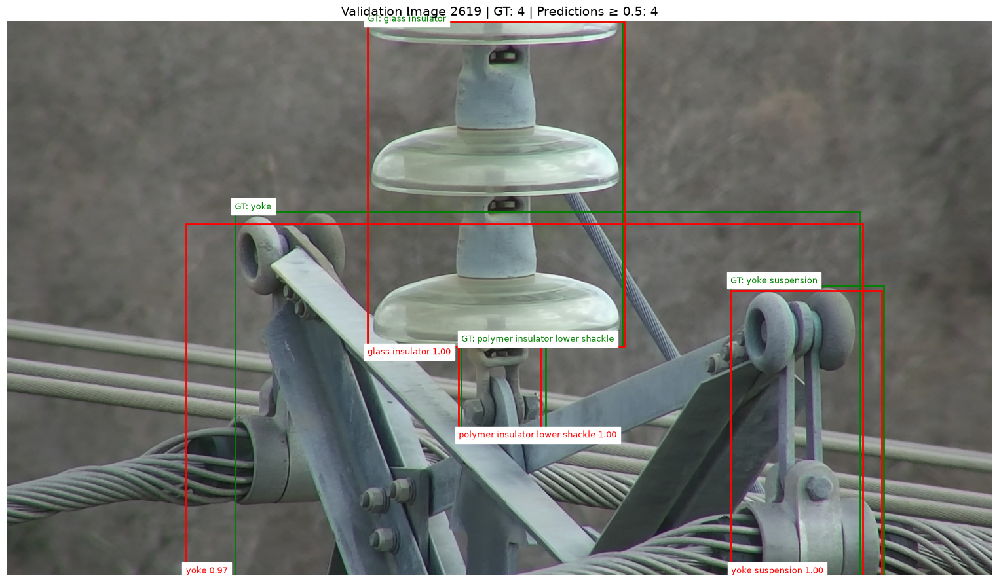

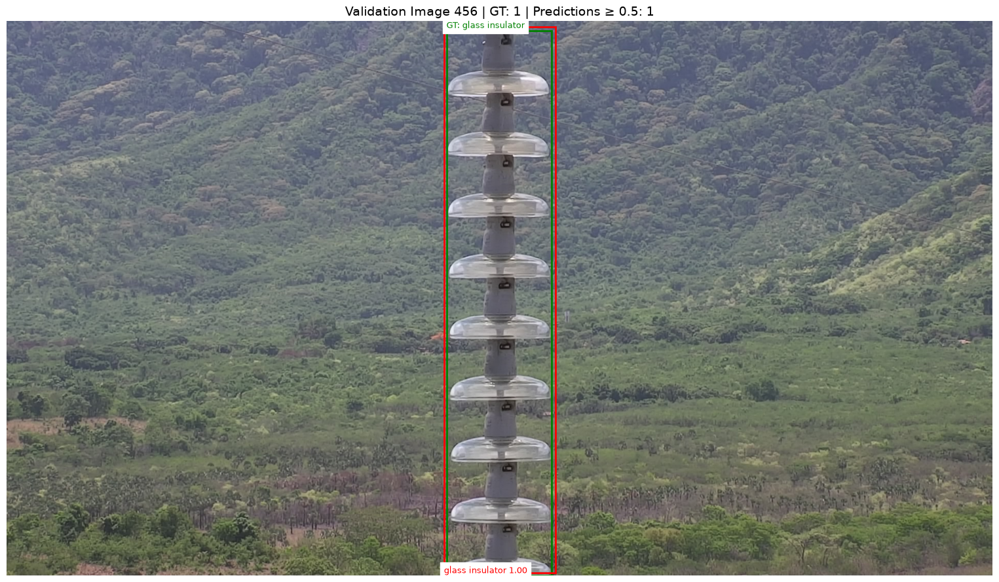

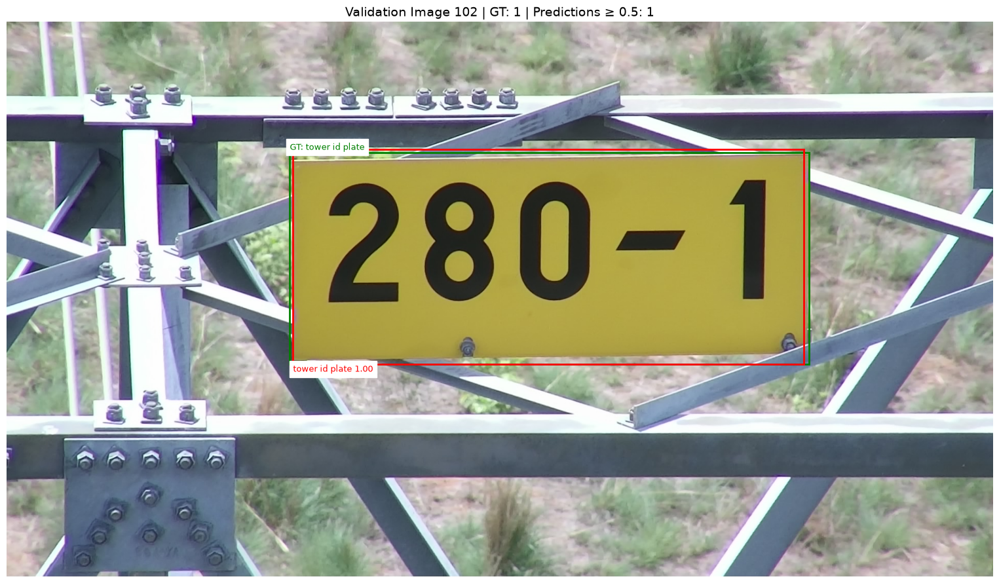

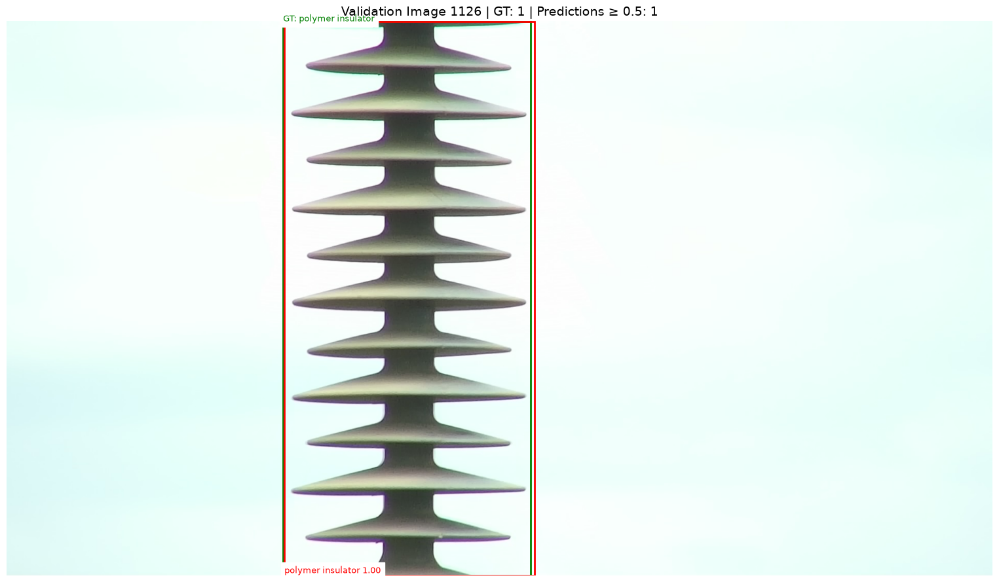


VISUALIZATION COMPLETED


In [29]:
# ============================================================
# STEP 49 — VISUALIZE VALIDATION PREDICTIONS
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import os
import random

print("=" * 60)
print("STEP 49 — VISUALIZING DETECTION RESULTS")
print("=" * 60)

# ------------------------------------------------------------
# Class names
# ------------------------------------------------------------

class_names = [
    "background",
    "yoke",
    "yoke suspension",
    "spacer",
    "stockbridge damper",
    "lightning rod shackle",
    "lightning rod suspension",
    "polymer insulator",
    "glass insulator",
    "tower id plate",
    "vari-grip",
    "polymer insulator lower shackle",
    "polymer insulator upper shackle",
    "polymer insulator tower shackle",
    "glass insulator big shackle",
    "glass insulator small shackle",
    "glass insulator tower shackle",
    "spiral damper",
    "sphere"
]

# ------------------------------------------------------------
# Confidence threshold
# ------------------------------------------------------------

CONFIDENCE_THRESHOLD = 0.50

# ------------------------------------------------------------
# Select validation images
# ------------------------------------------------------------

num_samples = 4

random.seed(42)

sample_indices = random.sample(
    range(len(val_dataset)),
    num_samples
)

print("Selected validation indices:", sample_indices)

# ------------------------------------------------------------
# Visualize
# ------------------------------------------------------------

for idx in sample_indices:

    # Get image
    image_tensor, target = val_dataset[idx]

    image = image_tensor.permute(1, 2, 0).numpy()

    prediction = all_predictions[idx]

    predicted_boxes = prediction["boxes"].numpy()
    predicted_labels = prediction["labels"].numpy()
    predicted_scores = prediction["scores"].numpy()

    ground_truth_boxes = target["boxes"].numpy()
    ground_truth_labels = target["labels"].numpy()

    # --------------------------------------------------------
    # Create figure
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(16, 9)
    )

    ax.imshow(image)

    # --------------------------------------------------------
    # Ground-truth boxes
    # --------------------------------------------------------

    for box, label in zip(
        ground_truth_boxes,
        ground_truth_labels
    ):

        xmin, ymin, xmax, ymax = box

        width = xmax - xmin
        height = ymax - ymin

        rect = patches.Rectangle(
            (xmin, ymin),
            width,
            height,
            linewidth=2,
            edgecolor="green",
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            xmin,
            max(ymin - 5, 0),
            f"GT: {class_names[int(label)]}",
            fontsize=9,
            color="green",
            backgroundcolor="white"
        )

    # --------------------------------------------------------
    # Predicted boxes
    # --------------------------------------------------------

    prediction_count = 0

    for box, label, score in zip(
        predicted_boxes,
        predicted_labels,
        predicted_scores
    ):

        if score < CONFIDENCE_THRESHOLD:
            continue

        xmin, ymin, xmax, ymax = box

        width = xmax - xmin
        height = ymax - ymin

        rect = patches.Rectangle(
            (xmin, ymin),
            width,
            height,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            xmin,
            min(ymax + 15, image.shape[0] - 5),
            f"{class_names[int(label)]} "
            f"{score:.2f}",
            fontsize=9,
            color="red",
            backgroundcolor="white"
        )

        prediction_count += 1

    # --------------------------------------------------------
    # Title
    # --------------------------------------------------------

    ax.set_title(
        f"Validation Image {idx} | "
        f"GT: {len(ground_truth_boxes)} | "
        f"Predictions ≥ {CONFIDENCE_THRESHOLD}: "
        f"{prediction_count}",
        fontsize=14
    )

    ax.axis("off")

    plt.tight_layout()
    plt.show()

print("\n" + "=" * 60)
print("VISUALIZATION COMPLETED")
print("=" * 60)

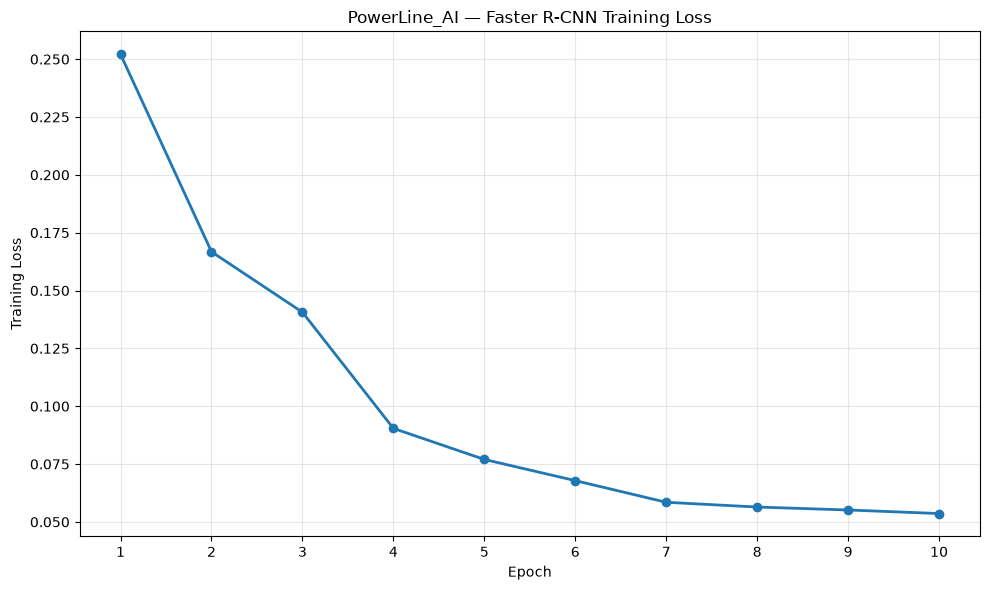

TRAINING LOSS CURVE GENERATED
Initial loss : 0.252100
Final loss   : 0.053617
Loss reduction: 78.73%


In [30]:
# ============================================================
# STEP 50 — TRAINING LOSS CURVE
# ============================================================

import matplotlib.pyplot as plt

# Recorded training results
epochs = [
    1, 2, 3, 4, 5,
    6, 7, 8, 9, 10
]

losses = [
    0.2521,
    0.166758,
    0.140621,
    0.090420,
    0.076993,
    0.067844,
    0.058481,
    0.056423,
    0.055148,
    0.053617
]

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    losses,
    marker="o",
    linewidth=2
)

plt.title(
    "PowerLine_AI — Faster R-CNN Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")

plt.xticks(epochs)

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()

print("=" * 60)
print("TRAINING LOSS CURVE GENERATED")
print("=" * 60)

print(f"Initial loss : {losses[0]:.6f}")
print(f"Final loss   : {losses[-1]:.6f}")

reduction = (
    (losses[0] - losses[-1])
    / losses[0]
) * 100

print(f"Loss reduction: {reduction:.2f}%")

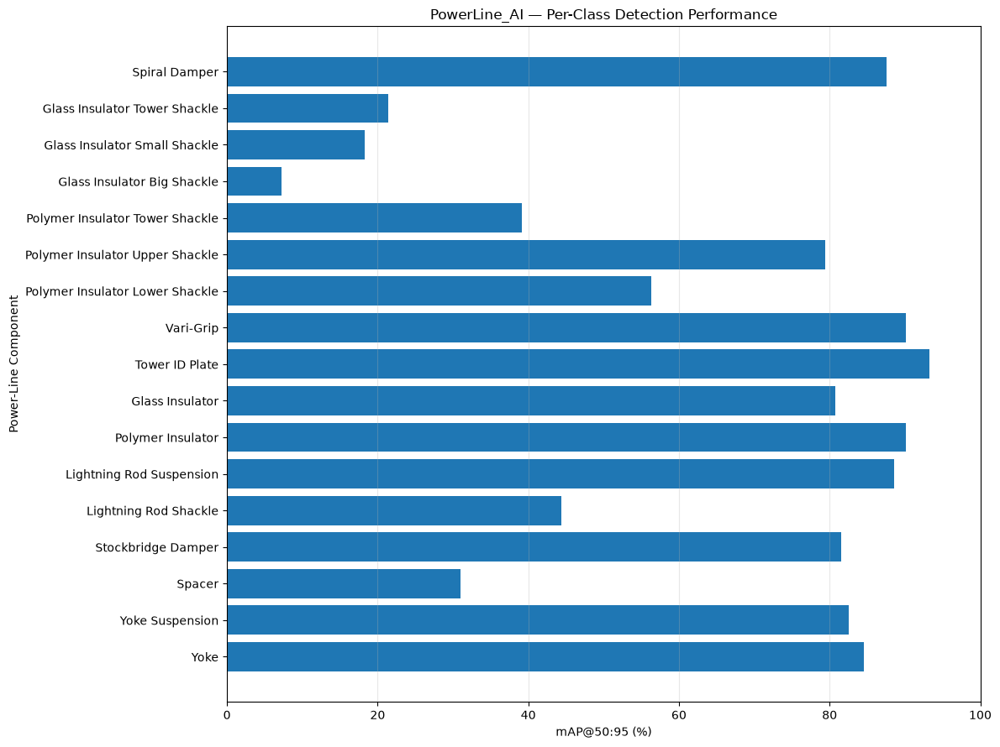

PER-CLASS mAP CHART GENERATED


In [31]:
# ============================================================
# STEP 51 — PER-CLASS mAP@50:95 CHART
# ============================================================

import matplotlib.pyplot as plt

# Class names
class_names = [
    "Yoke",
    "Yoke Suspension",
    "Spacer",
    "Stockbridge Damper",
    "Lightning Rod Shackle",
    "Lightning Rod Suspension",
    "Polymer Insulator",
    "Glass Insulator",
    "Tower ID Plate",
    "Vari-Grip",
    "Polymer Insulator Lower Shackle",
    "Polymer Insulator Upper Shackle",
    "Polymer Insulator Tower Shackle",
    "Glass Insulator Big Shackle",
    "Glass Insulator Small Shackle",
    "Glass Insulator Tower Shackle",
    "Spiral Damper",
    "Sphere"
]

# mAP@50:95 values from STEP 48B
class_map = [
    0.8456,
    0.8254,
    0.3105,
    0.8150,
    0.4437,
    0.8854,
    0.9016,
    0.8076,
    0.9325,
    0.9012,
    0.5633,
    0.7941,
    0.3913,
    0.0727,
    0.1831,
    0.2143,
    0.8755,
    None
]

# ------------------------------------------------------------
# Remove undefined class (Sphere)
# ------------------------------------------------------------

valid_names = []
valid_scores = []

for name, score in zip(class_names, class_map):

    if score is not None:
        valid_names.append(name)
        valid_scores.append(score * 100)

# ------------------------------------------------------------
# Create horizontal bar chart
# ------------------------------------------------------------

plt.figure(figsize=(12, 9))

plt.barh(
    valid_names,
    valid_scores
)

plt.xlabel("mAP@50:95 (%)")
plt.ylabel("Power-Line Component")
plt.title(
    "PowerLine_AI — Per-Class Detection Performance"
)

plt.xlim(0, 100)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.show()

print("=" * 60)
print("PER-CLASS mAP CHART GENERATED")
print("=" * 60)

In [32]:
# ============================================================
# STEP 52 — FINAL MODEL RESULTS SUMMARY
# ============================================================

print("=" * 70)
print("POWERLINE_AI — FINAL MODEL EVALUATION")
print("=" * 70)

print("\nMODEL")
print("-" * 70)
print("Architecture        : Faster R-CNN")
print("Backbone             : ResNet-50 + FPN")
print("Number of classes    : 18 power-line components")
print("Training epochs      : 10")
print("Training images      : 7,981")
print("Validation images    : 2,626")
print("GPU                  : NVIDIA GeForce RTX 2050")
print("Mixed Precision      : Enabled")

print("\nTRAINING")
print("-" * 70)
print("Initial loss         : 0.2521")
print("Final loss           : 0.053617")
print("Loss reduction       : 78.73%")

print("\nVALIDATION PERFORMANCE")
print("-" * 70)
print("mAP@50               : 82.90%")
print("mAP@50:95            : 63.31%")
print("mAP@75               : 66.69%")
print("mAR@100              : 68.73%")

print("\nBEST PERFORMING CLASSES")
print("-" * 70)
print("Tower ID Plate       : 93.25%")
print("Polymer Insulator    : 90.16%")
print("Vari-Grip            : 90.12%")
print("Lightning Rod Suspension : 88.54%")
print("Spiral Damper        : 87.55%")

print("\nLOWER PERFORMING CLASSES")
print("-" * 70)
print("Glass Insulator Big Shackle    : 7.27%")
print("Glass Insulator Small Shackle  : 18.31%")
print("Glass Insulator Tower Shackle  : 21.43%")
print("Spacer                         : 31.05%")
print("Polymer Insulator Tower Shackle: 39.13%")

print("\n" + "=" * 70)
print("FINAL EVALUATION COMPLETED")
print("=" * 70)

POWERLINE_AI — FINAL MODEL EVALUATION

MODEL
----------------------------------------------------------------------
Architecture        : Faster R-CNN
Backbone             : ResNet-50 + FPN
Number of classes    : 18 power-line components
Training epochs      : 10
Training images      : 7,981
Validation images    : 2,626
GPU                  : NVIDIA GeForce RTX 2050
Mixed Precision      : Enabled

TRAINING
----------------------------------------------------------------------
Initial loss         : 0.2521
Final loss           : 0.053617
Loss reduction       : 78.73%

VALIDATION PERFORMANCE
----------------------------------------------------------------------
mAP@50               : 82.90%
mAP@50:95            : 63.31%
mAP@75               : 66.69%
mAR@100              : 68.73%

BEST PERFORMING CLASSES
----------------------------------------------------------------------
Tower ID Plate       : 93.25%
Polymer Insulator    : 90.16%
Vari-Grip            : 90.12%
Lightning Rod Suspension :

In [36]:
# ============================================================
# STEP 53B — SET CORRECT TEST IMAGE PATH
# ============================================================

import os

IMAGE_PATH = r"C:\Users\pabit\Downloads\powerline_test.jpg.jpeg"

print("File exists:", os.path.exists(IMAGE_PATH))
print("Image path :", IMAGE_PATH)

File exists: True
Image path : C:\Users\pabit\Downloads\powerline_test.jpg.jpeg


STEP 53C — RUNNING NEW IMAGE PREDICTION
Image loaded successfully.
Image size: (1920, 1080)

Confidence threshold: 0.5
Detections: 1

DETECTION RESULTS
 1. polymer insulator                        Confidence: 0.7104


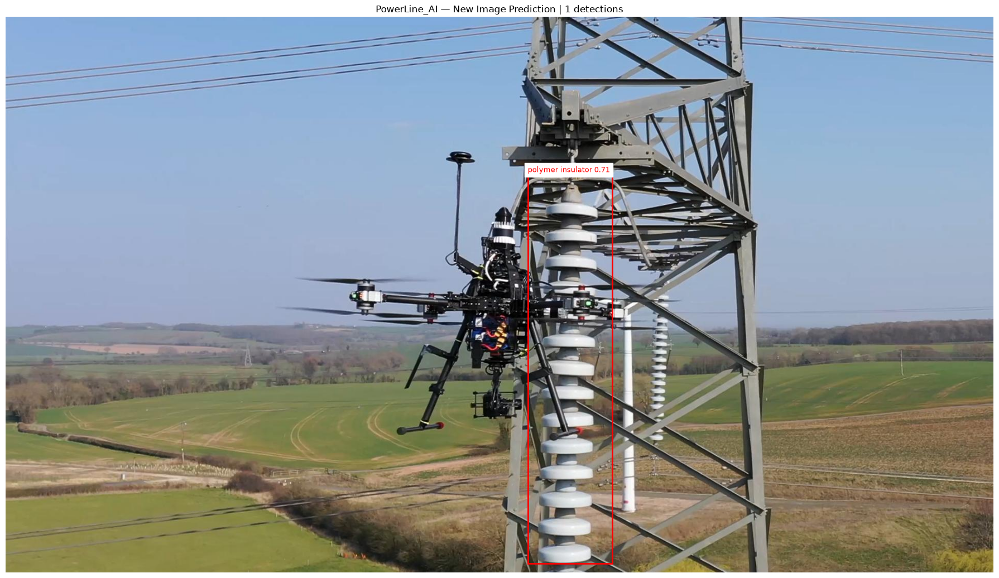


NEW IMAGE PREDICTION COMPLETED


In [37]:
# ============================================================
# STEP 53C — RUN MODEL PREDICTION
# ============================================================

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

print("=" * 60)
print("STEP 53C — RUNNING NEW IMAGE PREDICTION")
print("=" * 60)

# ------------------------------------------------------------
# Load image
# ------------------------------------------------------------

image = Image.open(IMAGE_PATH).convert("RGB")

print("Image loaded successfully.")
print("Image size:", image.size)

# ------------------------------------------------------------
# Convert image to tensor
# ------------------------------------------------------------

image_tensor = torch.from_numpy(
    np.array(image)
).permute(2, 0, 1).float() / 255.0

image_tensor = image_tensor.to(device)

# ------------------------------------------------------------
# Run Faster R-CNN
# ------------------------------------------------------------

model.eval()

with torch.no_grad():
    prediction = model([image_tensor])[0]

# ------------------------------------------------------------
# Move predictions to CPU
# ------------------------------------------------------------

boxes = prediction["boxes"].cpu()
labels = prediction["labels"].cpu()
scores = prediction["scores"].cpu()

# ------------------------------------------------------------
# Confidence threshold
# ------------------------------------------------------------

CONFIDENCE_THRESHOLD = 0.50

keep = scores >= CONFIDENCE_THRESHOLD

boxes = boxes[keep]
labels = labels[keep]
scores = scores[keep]

print("\nConfidence threshold:", CONFIDENCE_THRESHOLD)
print("Detections:", len(boxes))

# ------------------------------------------------------------
# Class names
# ------------------------------------------------------------

class_names = [
    "background",
    "yoke",
    "yoke suspension",
    "spacer",
    "stockbridge damper",
    "lightning rod shackle",
    "lightning rod suspension",
    "polymer insulator",
    "glass insulator",
    "tower id plate",
    "vari-grip",
    "polymer insulator lower shackle",
    "polymer insulator upper shackle",
    "polymer insulator tower shackle",
    "glass insulator big shackle",
    "glass insulator small shackle",
    "glass insulator tower shackle",
    "spiral damper",
    "sphere"
]

# ------------------------------------------------------------
# Print detections
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("DETECTION RESULTS")
print("=" * 60)

for i, (box, label, score) in enumerate(
    zip(boxes, labels, scores),
    start=1
):

    print(
        f"{i:2d}. "
        f"{class_names[int(label)]:<40} "
        f"Confidence: {score:.4f}"
    )

# ------------------------------------------------------------
# Visualize
# ------------------------------------------------------------

plt.figure(figsize=(18, 11))

plt.imshow(image)

ax = plt.gca()

for box, label, score in zip(
    boxes,
    labels,
    scores
):

    xmin, ymin, xmax, ymax = box.tolist()

    rect = patches.Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

    ax.text(
        xmin,
        max(ymin - 5, 0),
        f"{class_names[int(label)]} {score:.2f}",
        fontsize=9,
        color="red",
        backgroundcolor="white"
    )

plt.title(
    f"PowerLine_AI — New Image Prediction | "
    f"{len(boxes)} detections"
)

plt.axis("off")
plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("NEW IMAGE PREDICTION COMPLETED")
print("=" * 60)

In [1]:
import torch

path = r"D:\python\DLproject_checkpoints\checkpoint_epoch_10.pth"

checkpoint = torch.load(
    path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    print(list(checkpoint.keys()))

    state = checkpoint.get("model_state_dict", checkpoint)

    print("\nClassifier information:")

    for key in [
        "roi_heads.box_predictor.cls_score.weight",
        "roi_heads.box_predictor.cls_score.bias",
        "roi_heads.box_predictor.bbox_pred.weight"
    ]:
        if key in state:
            print(key, state[key].shape)
        else:
            print(key, "Not found")

Checkpoint type: <class 'dict'>

Checkpoint keys:
['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'loss']

Classifier information:
roi_heads.box_predictor.cls_score.weight torch.Size([19, 1024])
roi_heads.box_predictor.cls_score.bias torch.Size([19])
roi_heads.box_predictor.bbox_pred.weight torch.Size([76, 1024])


In [2]:
print("Epoch:", checkpoint["epoch"])
print("Training Loss:", checkpoint["loss"])

print("\nModel parameter examples:")
state = checkpoint["model_state_dict"]

for key in list(state.keys())[:15]:
    print(key, state[key].shape)

Epoch: 10
Training Loss: 0.05361724865949178

Model parameter examples:
backbone.body.conv1.weight torch.Size([64, 3, 7, 7])
backbone.body.bn1.weight torch.Size([64])
backbone.body.bn1.bias torch.Size([64])
backbone.body.bn1.running_mean torch.Size([64])
backbone.body.bn1.running_var torch.Size([64])
backbone.body.layer1.0.conv1.weight torch.Size([64, 64, 1, 1])
backbone.body.layer1.0.bn1.weight torch.Size([64])
backbone.body.layer1.0.bn1.bias torch.Size([64])
backbone.body.layer1.0.bn1.running_mean torch.Size([64])
backbone.body.layer1.0.bn1.running_var torch.Size([64])
backbone.body.layer1.0.conv2.weight torch.Size([64, 64, 3, 3])
backbone.body.layer1.0.bn2.weight torch.Size([64])
backbone.body.layer1.0.bn2.bias torch.Size([64])
backbone.body.layer1.0.bn2.running_mean torch.Size([64])
backbone.body.layer1.0.bn2.running_var torch.Size([64])


In [3]:
state = checkpoint["model_state_dict"]

print("Total model parameters:",
      sum(p.numel() for p in state.values()))

print("\nImportant architecture parameters:")

for key in state:
    if any(x in key for x in [
        "backbone.fpn",
        "backbone.fpn",
        "rpn.head",
        "roi_heads.box_head",
        "roi_heads.box_predictor"
    ]):
        print(key, tuple(state[key].shape))

Total model parameters: 41492526

Important architecture parameters:
backbone.fpn.inner_blocks.0.0.weight (256, 256, 1, 1)
backbone.fpn.inner_blocks.0.0.bias (256,)
backbone.fpn.inner_blocks.1.0.weight (256, 512, 1, 1)
backbone.fpn.inner_blocks.1.0.bias (256,)
backbone.fpn.inner_blocks.2.0.weight (256, 1024, 1, 1)
backbone.fpn.inner_blocks.2.0.bias (256,)
backbone.fpn.inner_blocks.3.0.weight (256, 2048, 1, 1)
backbone.fpn.inner_blocks.3.0.bias (256,)
backbone.fpn.layer_blocks.0.0.weight (256, 256, 3, 3)
backbone.fpn.layer_blocks.0.0.bias (256,)
backbone.fpn.layer_blocks.1.0.weight (256, 256, 3, 3)
backbone.fpn.layer_blocks.1.0.bias (256,)
backbone.fpn.layer_blocks.2.0.weight (256, 256, 3, 3)
backbone.fpn.layer_blocks.2.0.bias (256,)
backbone.fpn.layer_blocks.3.0.weight (256, 256, 3, 3)
backbone.fpn.layer_blocks.3.0.bias (256,)
rpn.head.conv.0.0.weight (256, 256, 3, 3)
rpn.head.conv.0.0.bias (256,)
rpn.head.cls_logits.weight (3, 256, 1, 1)
rpn.head.cls_logits.bias (3,)
rpn.head.bbox_pre

In [4]:
import torch
import torchvision
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn
)
from torchvision.models.detection.faster_rcnn import (
    FastRCNNPredictor
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

num_classes = 19

model = fasterrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None
)

in_features = model.roi_heads.box_predictor.cls_score.in_features

model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes
)

checkpoint = torch.load(
    r"D:\python\DLproject_checkpoints\checkpoint_epoch_10.pth",
    map_location="cpu",
    weights_only=True
)

result = model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model.to(device)
model.eval()

print("Checkpoint loaded successfully!")
print("Device:", device)
print("Number of classes:", num_classes)
print("Missing keys:", result.missing_keys)
print("Unexpected keys:", result.unexpected_keys)

Checkpoint loaded successfully!
Device: cuda
Number of classes: 19
Missing keys: []
Unexpected keys: []


In [5]:
from PIL import Image
import torchvision.transforms as T
import matplotlib.pyplot as plt

# Select a validation image
image_path = r"YOUR_VALIDATION_IMAGE_PATH.jpg"

image = Image.open(image_path).convert("RGB")

transform = T.ToTensor()
image_tensor = transform(image).to(device)

model.eval()

with torch.no_grad():
    predictions = model([image_tensor])

pred = predictions[0]

boxes = pred["boxes"].cpu()
labels = pred["labels"].cpu()
scores = pred["scores"].cpu()

threshold = 0.50
keep = scores >= threshold

print("Total detections:", keep.sum().item())

for label, score, box in zip(
    labels[keep],
    scores[keep],
    boxes[keep]
):
    print(
        f"Class ID: {label.item()}, "
        f"Confidence: {score.item():.4f}, "
        f"Box: {box.tolist()}"
    )

plt.figure(figsize=(12, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'YOUR_VALIDATION_IMAGE_PATH.jpg'

In [6]:
import os
from pathlib import Path

# Set your actual InsPLAD dataset directory
DATASET_DIR = Path(r"D:\python\InsPLAD")

print("Dataset exists:", DATASET_DIR.exists())

if DATASET_DIR.exists():
    images = list(DATASET_DIR.rglob("*.jpg"))
    images += list(DATASET_DIR.rglob("*.JPG"))

    print("Total images found:", len(images))

    for img in images[:5]:
        print(img)
else:
    print("Please correct DATASET_DIR to your InsPLAD dataset location.")

Dataset exists: True
Total images found: 21122
D:\python\InsPLAD\InsPLAD-det\train\1-1_DJI_0569.jpg
D:\python\InsPLAD\InsPLAD-det\train\1-1_DJI_0571.jpg
D:\python\InsPLAD\InsPLAD-det\train\1-1_DJI_0572.jpg
D:\python\InsPLAD\InsPLAD-det\train\1-1_DJI_0573.jpg
D:\python\InsPLAD\InsPLAD-det\train\1-1_DJI_0574.jpg


Image: D:\python\InsPLAD\InsPLAD-det\train\1-1_DJI_0569.jpg
Total detections: 1
Class ID: 9, Confidence: 0.9988, Bounding Box: [717.12744140625, 261.5579528808594, 1386.9891357421875, 531.5753784179688]


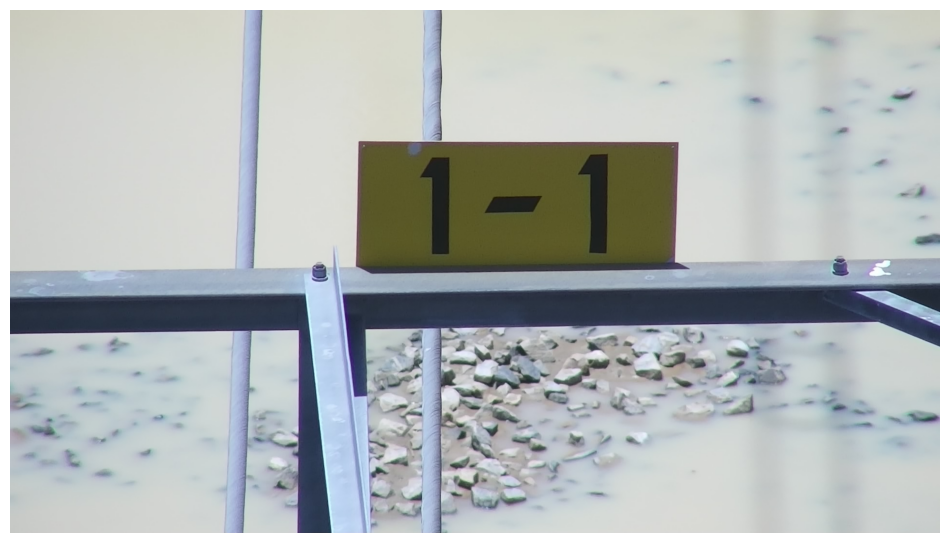

In [7]:
from PIL import Image
import torchvision.transforms as T
import matplotlib.pyplot as plt
import torch

# Select first available image
image_path = images[0]

image = Image.open(image_path).convert("RGB")

image_tensor = T.ToTensor()(image).to(device)

model.eval()

with torch.no_grad():
    predictions = model([image_tensor])

pred = predictions[0]

boxes = pred["boxes"].cpu()
labels = pred["labels"].cpu()
scores = pred["scores"].cpu()

threshold = 0.50
keep = scores >= threshold

print("Image:", image_path)
print("Total detections:", keep.sum().item())

for label, score, box in zip(
    labels[keep],
    scores[keep],
    boxes[keep]
):
    print(
        f"Class ID: {label.item()}, "
        f"Confidence: {score.item():.4f}, "
        f"Bounding Box: {box.tolist()}"
    )

plt.figure(figsize=(12, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

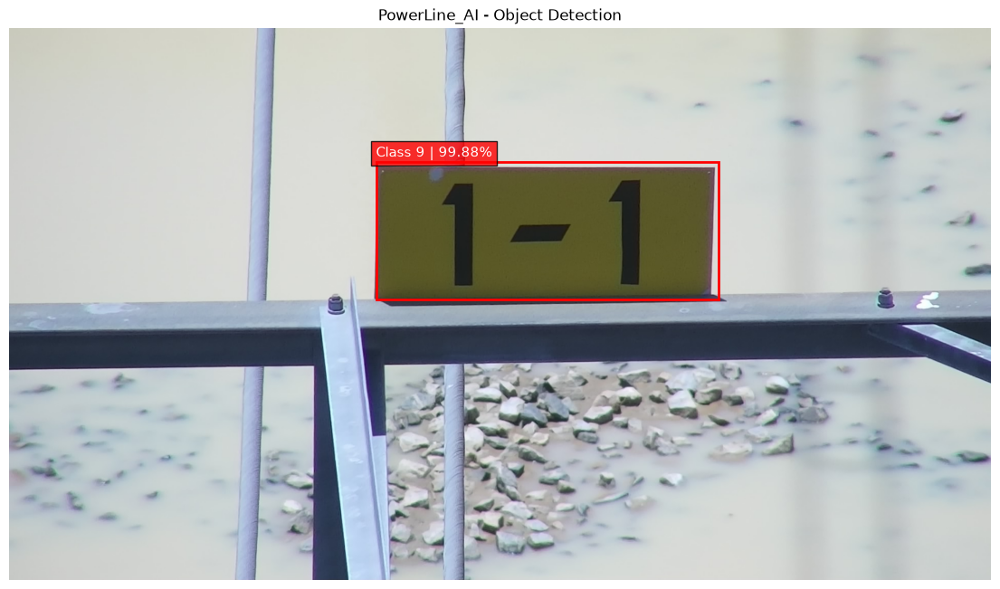

In [8]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(14, 9))
ax.imshow(image)

for box, label, score in zip(
    boxes[keep],
    labels[keep],
    scores[keep]
):
    x1, y1, x2, y2 = box.tolist()

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        max(0, y1 - 10),
        f"Class {label.item()} | {score.item():.2%}",
        color="white",
        fontsize=11,
        bbox=dict(facecolor="red", alpha=0.8)
    )

ax.set_title("PowerLine_AI - Object Detection")
ax.axis("off")
plt.show()

In [9]:
print("Class mapping:")

for class_id, class_name in enumerate(class_names):
    print(class_id, ":", class_name)

Class mapping:


NameError: name 'class_names' is not defined

In [10]:
import json
from pathlib import Path

dataset_dir = Path(r"D:\python\InsPLAD\InsPLAD-det")

annotation_files = list(
    dataset_dir.rglob("instances_train.json")
)

print("Annotation files:", annotation_files)

annotation_path = annotation_files[0]

with open(annotation_path, "r") as f:
    data = json.load(f)

image_name = "1-1_DJI_0569.jpg"

image_info = next(
    (img for img in data["images"]
     if img["file_name"].replace("\\", "/").endswith(image_name)),
    None
)

if image_info:
    print("\nImage ID:", image_info["id"])

    annotations = [
        ann for ann in data["annotations"]
        if ann["image_id"] == image_info["id"]
    ]

    category_map = {
        cat["id"]: cat["name"]
        for cat in data["categories"]
    }

    print("\nGround Truth Annotations:")

    for ann in annotations:
        category_id = ann["category_id"]

        print(
            "Category ID:", category_id,
            "| Name:", category_map.get(category_id),
            "| Bounding Box:", ann["bbox"]
        )

else:
    print("Image not found in training annotations.")

Annotation files: [WindowsPath('D:/python/InsPLAD/InsPLAD-det/annotations/instances_train.json')]

Image ID: 7032

Ground Truth Annotations:
Category ID: 9 | Name: tower id plate | Bounding Box: [711, 267, 672, 264]


In [11]:
for i, name in enumerate(class_names):
    print(f"Class ID {i}: {name}")

NameError: name 'class_names' is not defined

In [12]:
import json

annotation_path = (
    r"D:\python\InsPLAD\InsPLAD-det"
    r"\annotations\instances_train.json"
)

with open(annotation_path, "r") as f:
    data = json.load(f)

categories = sorted(
    data["categories"],
    key=lambda x: x["id"]
)

print("DATASET CLASS MAPPING")
print("-" * 40)

for category in categories:
    print(
        f"Category ID: {category['id']} "
        f"| Name: {category['name']}"
    )

print("\nTotal component categories:", len(categories))

DATASET CLASS MAPPING
----------------------------------------
Category ID: 1 | Name: yoke
Category ID: 2 | Name: yoke suspension
Category ID: 3 | Name: spacer
Category ID: 4 | Name: stockbridge damper
Category ID: 5 | Name: lightning rod shackle
Category ID: 6 | Name: lightning rod suspension
Category ID: 7 | Name: polymer insulator
Category ID: 8 | Name: glass insulator
Category ID: 9 | Name: tower id plate
Category ID: 10 | Name: vari-grip
Category ID: 11 | Name: polymer insulator lower shackle
Category ID: 12 | Name: polymer insulator upper shackle
Category ID: 13 | Name: polymer insulator tower shackle
Category ID: 14 | Name: glass insulator big shackle
Category ID: 15 | Name: glass insulator small shackle
Category ID: 16 | Name: glass insulator tower shackle
Category ID: 17 | Name: spiral damper
Category ID: 18 | Name: sphere

Total component categories: 18


In [13]:
import json

annotation_path = (
    r"D:\python\InsPLAD\InsPLAD-det"
    r"\annotations\instances_train.json"
)

with open(annotation_path, "r") as f:
    data = json.load(f)

categories = sorted(
    data["categories"],
    key=lambda x: x["id"]
)

class_names = ["Background"] + [
    category["name"]
    for category in categories
]

print("Total classes:", len(class_names))

for class_id, name in enumerate(class_names):
    print(f"{class_id}: {name}")

assert len(class_names) == 19
assert all(
    category["id"] == i
    for i, category in enumerate(categories, start=1)
)

print("\nClass mapping verified!")

Total classes: 19
0: Background
1: yoke
2: yoke suspension
3: spacer
4: stockbridge damper
5: lightning rod shackle
6: lightning rod suspension
7: polymer insulator
8: glass insulator
9: tower id plate
10: vari-grip
11: polymer insulator lower shackle
12: polymer insulator upper shackle
13: polymer insulator tower shackle
14: glass insulator big shackle
15: glass insulator small shackle
16: glass insulator tower shackle
17: spiral damper
18: sphere

Class mapping verified!
